> **Revised version.** Fixes: mixed-effects crash, non-idempotent column drop, missing pip packages, broken Stage 1 stacking, optimistic blending threshold, near-uniform weighted averaging, plus a new F1 comparison (3.13f). Outputs from the first changed cell onward were cleared because the old numbers no longer apply: use *Run All*.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/busygeek/smx-concentration/SMX_concentration.csv
/kaggle/input/datasets/busygeek/smx-concentration/SMX_occurrence.csv


In [2]:
df_occ=pd.read_csv("/kaggle/input/datasets/busygeek/smx-concentration/SMX_occurrence.csv")
df_conc=pd.read_csv("/kaggle/input/datasets/busygeek/smx-concentration/SMX_concentration.csv")

In [3]:
print('occurrence:', df_occ.shape, '| concentration:', df_conc.shape)

occurrence: (1502, 41) | concentration: (871, 37)


In [4]:
df_occ.shape

(1502, 41)

In [5]:
df_occ.head()

,site_id,country,latitude,longitude,sampling_date,water_matrix,concentration_ng_L,LoD,LoQ,detection_status,...,dist_to_urban_area,pH,EC,TOC,COD,nutrients,turbidity,suspended_solids,Y_occ,Y_det
0,771,Italy,45.551944,8.973056,2006-12-13,river/lake,131.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
1,772,Italy,45.518889,9.041944,2006-12-13,river/lake,117.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
2,773,Italy,45.296667,9.388889,2006-06-29,river/lake,60.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
3,774,Italy,45.538056,9.182222,2006-10-04,river/lake,49.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
4,775,Italy,45.889167,11.605000,2006-06-29,river/lake,13.0,0.5,1.0,quantified,...,0.141435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1


In [6]:
df_conc.head()

,site_id,country,latitude,longitude,sampling_date,water_matrix,concentration_ng_L,month,year,day_of_year,...,dist_to_WWTP,dist_to_urban_area,pH,EC,TOC,COD,nutrients,turbidity,suspended_solids,Y_conc
0,771,Italy,45.551944,8.973056,2006-12-13,river/lake,131.0,12.0,2006.0,347.0,...,1.245786,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.120574
1,772,Italy,45.518889,9.041944,2006-12-13,river/lake,117.0,12.0,2006.0,347.0,...,4.349366,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.071882
2,773,Italy,45.296667,9.388889,2006-06-29,river/lake,60.0,6.0,2006.0,180.0,...,0.782883,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.785330
3,774,Italy,45.538056,9.182222,2006-10-04,river/lake,49.0,10.0,2006.0,277.0,...,1.940980,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.698970
4,775,Italy,45.889167,11.605000,2006-06-29,river/lake,13.0,6.0,2006.0,180.0,...,8.793537,0.141435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.146128


In [7]:
missing = pd.DataFrame({
    'Missing Count': df_occ.isnull().sum(),
    'Missing Percentage': (df_occ.isnull().sum() / len(df_occ)) * 100
})

missing = missing.sort_values('Missing Percentage', ascending=False)

print(missing)

                     Missing Count  Missing Percentage
COD                           1502          100.000000
turbidity                     1498           99.733688
nutrients                     1469           97.802929
TOC                           1416           94.274301
suspended_solids              1406           93.608522
pH                            1349           89.813582
EC                            1331           88.615180
rainfall_anomaly               249           16.577896
air_temperature                225           14.980027
evapotranspiration             225           14.980027
rainfall_1d                    225           14.980027
rainfall_7d                    225           14.980027
rainfall_30d                   225           14.980027
population_density             162           10.785619
month_sin                      144            9.587217
season                         144            9.587217
month                          144            9.587217
sampling_d

In [8]:
missing = pd.DataFrame({
    'Missing Count': df_conc.isnull().sum(),
    'Missing Percentage': (df_conc.isnull().sum() / len(df_conc)) * 100
})

missing = missing.sort_values('Missing Percentage', ascending=False)

print(missing)

                     Missing Count  Missing Percentage
COD                            871          100.000000
turbidity                      869           99.770379
nutrients                      848           97.359357
TOC                            798           91.618829
suspended_solids               789           90.585534
pH                             750           86.107922
EC                             739           84.845006
rainfall_anomaly                90           10.332951
rainfall_1d                     75            8.610792
air_temperature                 75            8.610792
rainfall_30d                    75            8.610792
evapotranspiration              75            8.610792
rainfall_7d                     75            8.610792
season                          59            6.773823
month_cos                       59            6.773823
month                           59            6.773823
month_sin                       59            6.773823
sampling_d

In [9]:
df_occ = df_occ.drop(columns=df_occ.columns[df_occ.isnull().mean() >= 0.70])

In [10]:
df_conc = df_conc.drop(columns=df_conc.columns[df_conc.isnull().mean() >= 0.70])

In [11]:
df_occ.drop(columns=['pct_industrial_land','day_of_year'], inplace=True, errors='ignore')
df_conc.drop(columns=['pct_industrial_land', 'day_of_year'], inplace=True, errors='ignore')

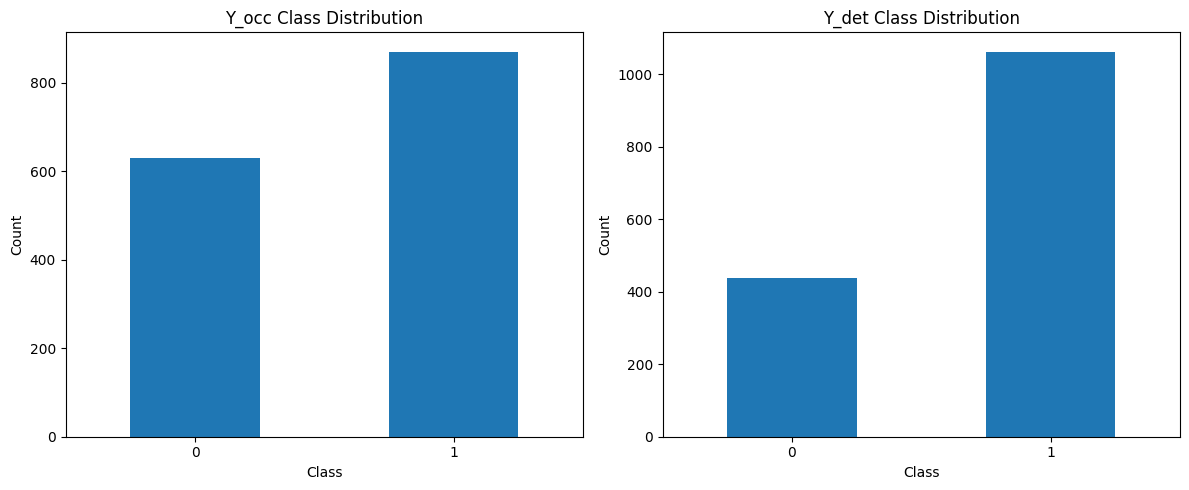

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ---------------- Y_occ ----------------
df_occ['Y_occ'].value_counts().sort_index().plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Y_occ Class Distribution')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['0', '1'], rotation=0)

# ---------------- Y_det ----------------
df_occ['Y_det'].value_counts().sort_index().plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Y_det Class Distribution')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(['0', '1'], rotation=0)

plt.tight_layout()
plt.show()

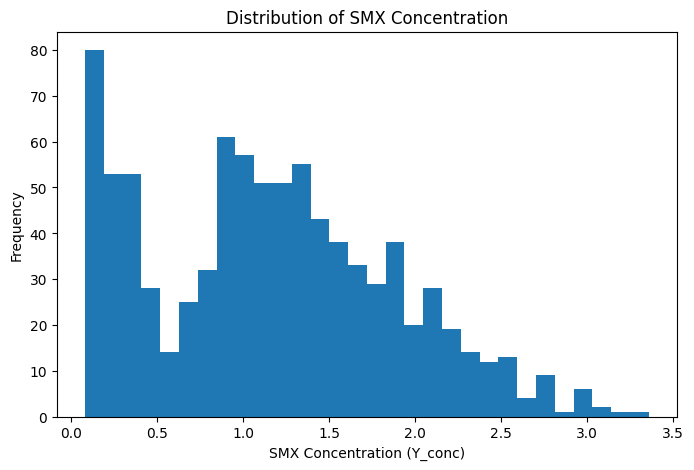

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_conc['Y_conc'].dropna(),
    bins=30
)

plt.xlabel('SMX Concentration (Y_conc)')
plt.ylabel('Frequency')
plt.title('Distribution of SMX Concentration')

plt.show()

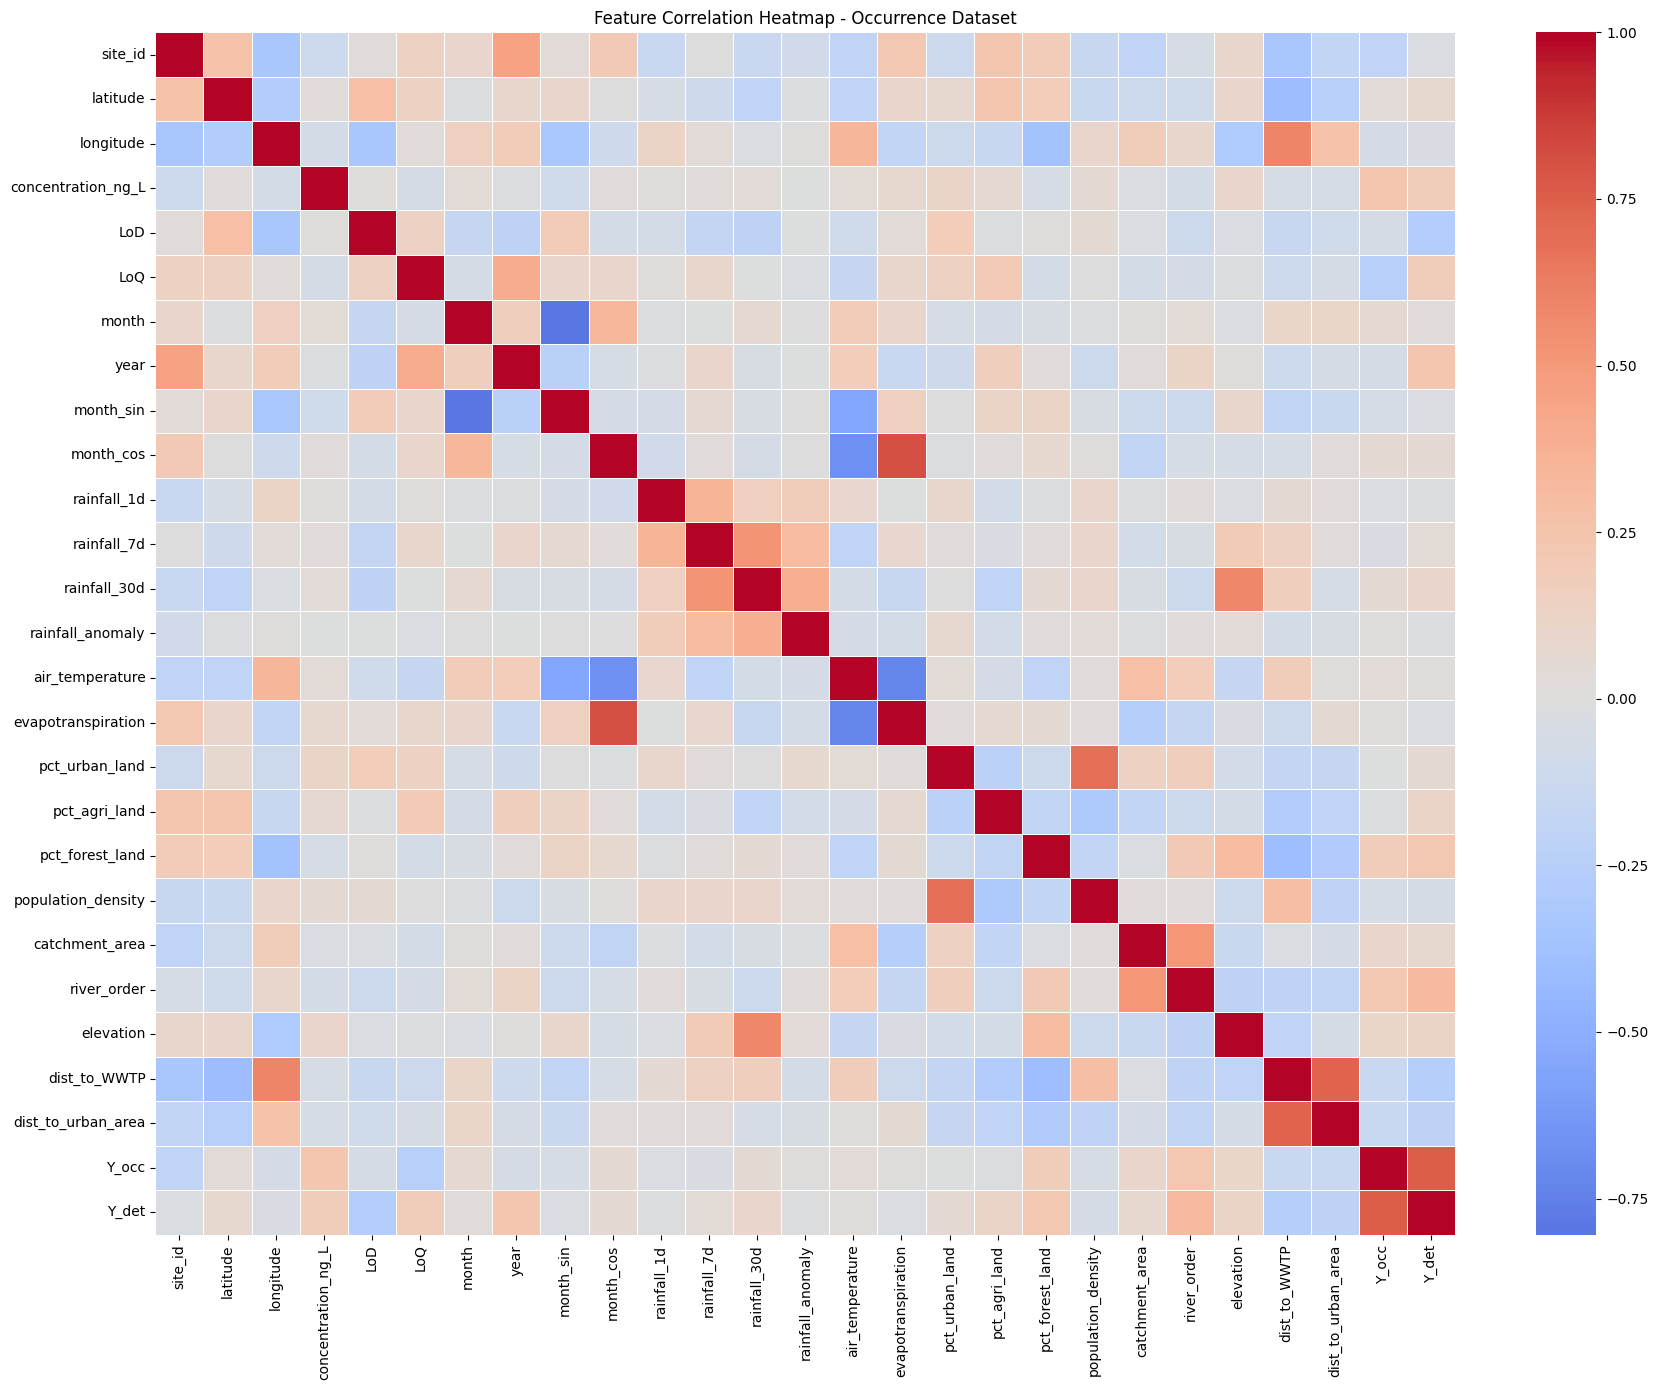

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_occ = df_occ.select_dtypes(include='number')

# Correlation matrix
corr_occ = numeric_occ.corr()

# Plot
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_occ,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap - Occurrence Dataset')
plt.tight_layout()
plt.show()

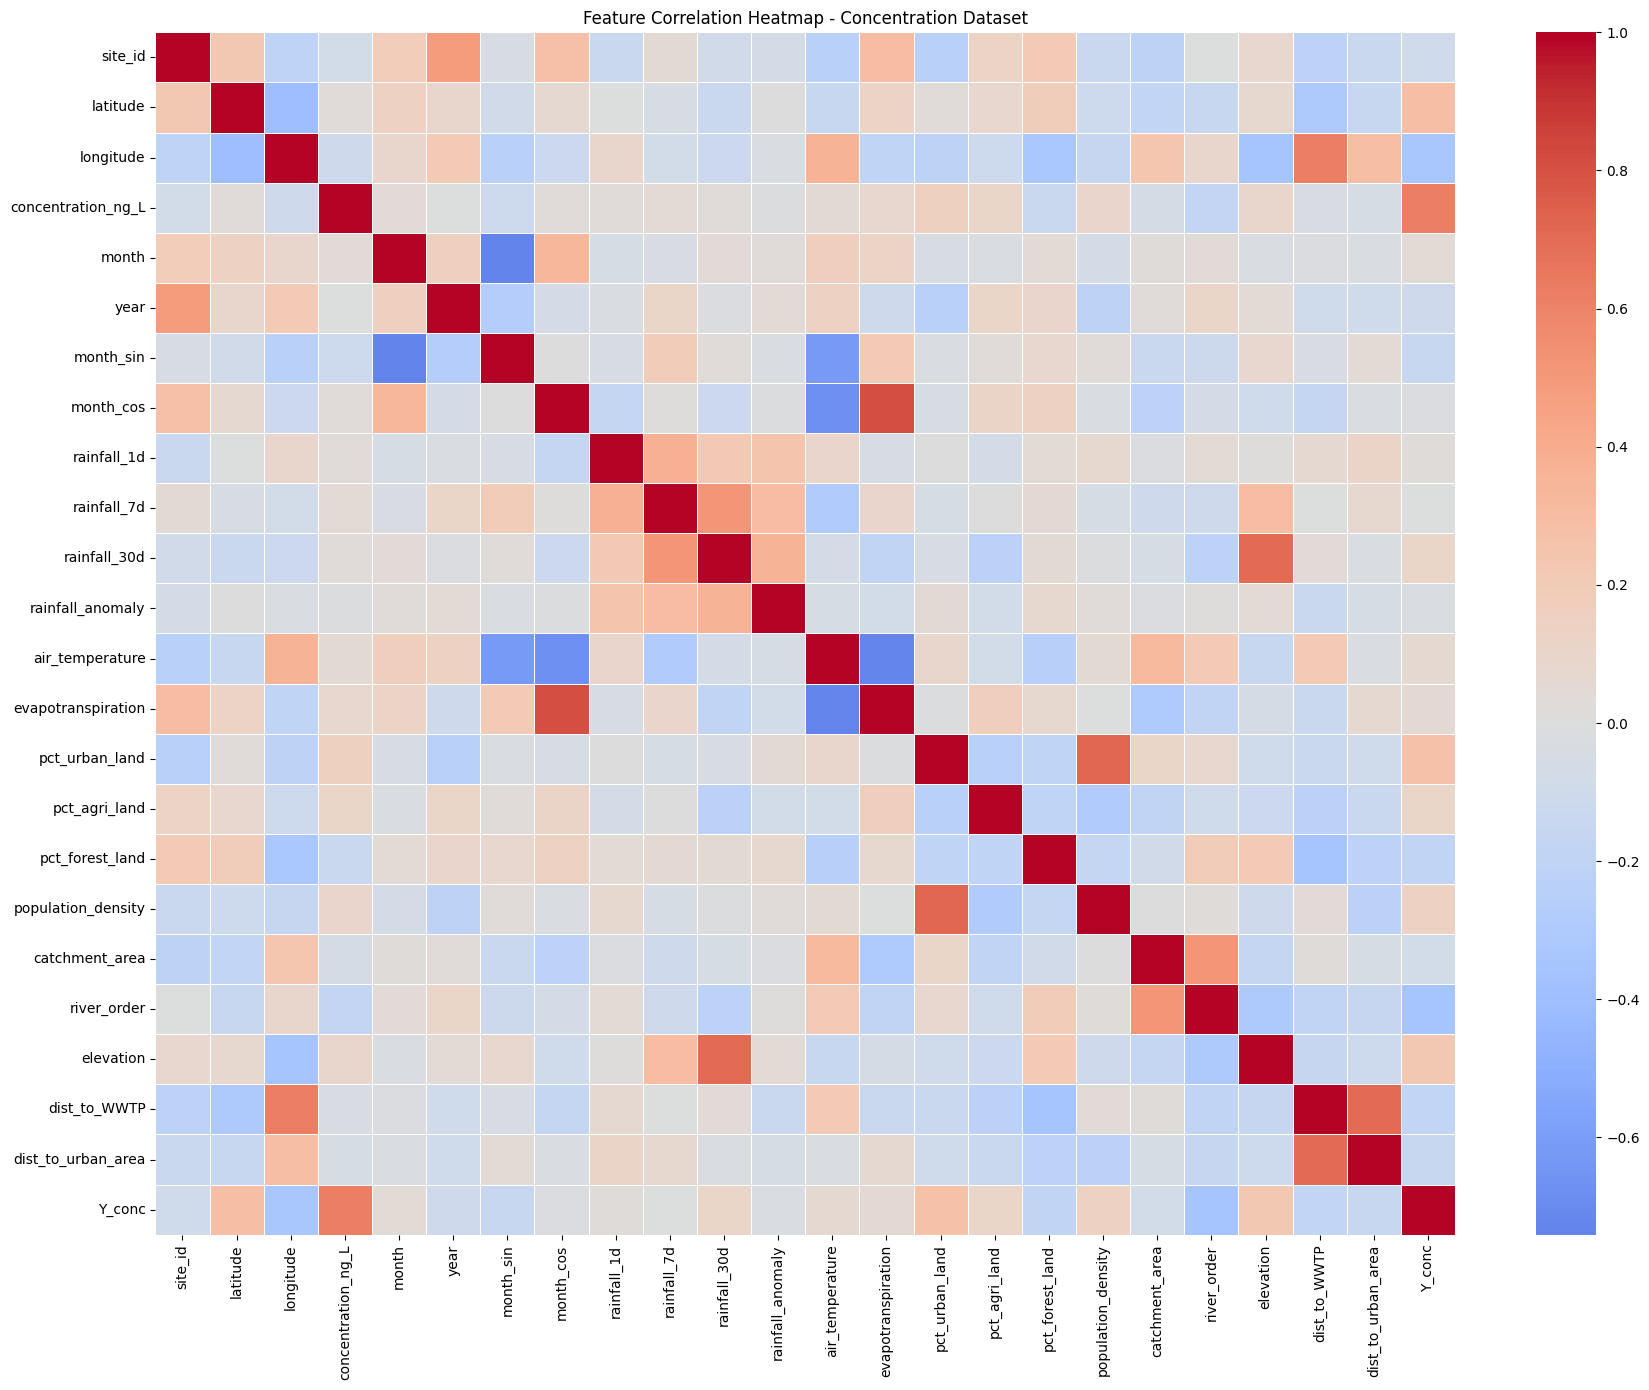

In [15]:
# Select numerical columns
numeric_conc = df_conc.select_dtypes(include='number')

# Correlation matrix
corr_conc = numeric_conc.corr()

# Plot
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_conc,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap - Concentration Dataset')
plt.tight_layout()
plt.show()

In [16]:
# Strong feature-feature correlations
corr = df_conc.select_dtypes(include='number').corr()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

strong_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={
        'level_0': 'Feature 1',
        'level_1': 'Feature 2',
        0: 'Correlation'
    })
)

strong_pairs['Abs_Correlation'] = strong_pairs['Correlation'].abs()

strong_pairs = strong_pairs.sort_values(
    'Abs_Correlation',
    ascending=False
)

print(strong_pairs[strong_pairs['Abs_Correlation'] >= 0.7])

           Feature 1           Feature 2  Correlation  Abs_Correlation
145        month_cos  evapotranspiration     0.815745         0.815745
87             month           month_sin    -0.740713         0.740713
210  air_temperature  evapotranspiration    -0.731243         0.731243
233   pct_urban_land  population_density     0.714492         0.714492
273     dist_to_WWTP  dist_to_urban_area     0.706929         0.706929
194     rainfall_30d           elevation     0.706670         0.706670


In [17]:
!pip install -q optuna imbalanced-learn xgboost catboost statsmodels interpret

ERROR: Could not find a version that satisfies the requirement interpret (from versions: none)
ERROR: No matching distribution found for interpret


# Applying paper Sections 3.6 – 3.13 to the SMX notebook

**Important fix first.** The previous modelling cells fed `concentration_ng_L`, `detection_status`, `LoD`, `LoQ` and `sampling_date` into the occurrence model. `Y_occ` is derived directly from `detection_status`, so those columns *are* the answer. This is why the SMOTE model scored 1.000 on everything. All of them (and `Y_det`) are removed in Section 3.6, and the random stratified split is replaced by the grouped (country-level) split required by Section 3.11.

Everything below follows the paper:

| Section | What is implemented |
|---|---|
| 3.6 | Dataset A (occurrence) and Dataset B (log10(C+1), quantified only) |
| 3.7 | Baselines: logistic regression, GAM-style spline logistic, linear regression, Tobit, mixed-effects |
| 3.8 | RF, XGBoost, CatBoost, SVM/SVR, EBM |
| 3.9 | Class weights, SMOTE sensitivity (training data only), PR-AUC, validation-set threshold |
| 3.10 | Optuna search (paper ranges), validation PR-AUC / RMSE |
| 3.11 | Grouped 70/15/15 split, leave-one-country-out, temporal, water-matrix transfer |
| 3.12 | Full metric set, calibration slope and plot, ng/L back-transformed errors |
| 3.13 | Quantile regression + conformal intervals, calibrated probabilities, uncertainty categories |

In [18]:
import warnings, re
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import optimize, stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC, SVR
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)

from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier, CatBoostRegressor
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import optuna

try:
    import statsmodels.api as sm
    HAS_SM = True
except ImportError:
    HAS_SM = False
try:
    from interpret.glassbox import ExplainableBoostingClassifier
    HAS_EBM = True
except Exception:
    HAS_EBM = False
print('statsmodels:', HAS_SM, '| interpret (EBM):', HAS_EBM)

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style('whitegrid')

# ------------------------------- CONFIG -------------------------------------
RANDOM_STATE        = 42
N_TRIALS            = 50      # paper: 50-100 per model. Use 10 for a quick dry run.
N_JOBS              = -1
MIN_COUNTRY_N       = 25      # LOCO: minimum rows for a country to be held out
MIN_MATRIX_N        = 50      # matrix-transfer: minimum rows for a held-out matrix
INCLUDE_COUNTRY     = False   # country one-hot cannot transfer to unseen countries
INCLUDE_COORDS      = False   # lat/lon act as country/site identifiers
THRESHOLD_CRITERION = 'balanced_accuracy'   # or 'f1'
CALIBRATION         = 'isotonic'            # or 'platt'
LOCO_MODELS         = ['Logistic Regression', 'Random Forest', 'XGBoost', 'CatBoost']

statsmodels: True | interpret (EBM): False


## 3.6 Construction of modelling datasets

* **Dataset A (occurrence):** one row per sample, target `Y_occ`.
* **Dataset B (conditional concentration):** quantified samples only, target `Y_conc = log10(C + 1)`.

Columns removed from the feature matrices: target-derived or method-dependent columns (`Y_occ`, `Y_det`, `Y_conc`, `concentration_ng_L`, `detection_status`, `LoD`, `LoQ`), identifiers (`site_id`, `sampling_date`) and, by default, `country` and coordinates (they identify the group being held out in Section 3.11). The water-quality columns were already dropped earlier because they are 85–100 % missing.

In [19]:
df_occ  = df_occ.reset_index(drop=True)
df_conc = df_conc.reset_index(drop=True)

# How is Y_occ defined? (below-LoQ detections are labelled 0 if this shows them under Y_occ = 0)
print(pd.crosstab(df_occ['detection_status'], df_occ['Y_occ']))
print('\nY_conc == log10(C+1)?', np.allclose(df_conc['Y_conc'], np.log10(df_conc['concentration_ng_L'] + 1)))

LEAKY_OR_ID = ['Y_occ', 'Y_det', 'Y_conc', 'site_id', 'sampling_date',
               'concentration_ng_L', 'detection_status', 'LoD', 'LoQ']
extra_drop = []
if not INCLUDE_COUNTRY: extra_drop.append('country')
if not INCLUDE_COORDS:  extra_drop += ['latitude', 'longitude']

XA_full = df_occ.drop(columns=LEAKY_OR_ID + extra_drop, errors='ignore')
XB_full = df_conc.drop(columns=LEAKY_OR_ID + extra_drop, errors='ignore')
FEATURES = [c for c in XA_full.columns if c in XB_full.columns]   # same feature set for A and B

X_occ,  y_occ  = XA_full[FEATURES].copy(), df_occ['Y_occ'].astype(int)
X_conc, y_conc = XB_full[FEATURES].copy(), df_conc['Y_conc'].astype(float)

print(f'\nDataset A: {X_occ.shape}, prevalence of Y_occ = {y_occ.mean():.3f}')
print(f'Dataset B: {X_conc.shape}, Y_conc mean = {y_conc.mean():.3f}')
print('Features:', FEATURES)

# Leakage guard: no single feature should separate the classes almost perfectly
def univariate_auc_scan(X, y, top=8):
    rows = []
    for c in X.select_dtypes(include=np.number).columns:
        m = X[c].notna()
        if m.sum() > 20 and y[m].nunique() == 2:
            a = roc_auc_score(y[m], X.loc[m, c])
            rows.append((c, max(a, 1 - a)))
    return (pd.DataFrame(rows, columns=['feature', 'AUC (best direction)'])
            .sort_values('AUC (best direction)', ascending=False).head(top))
print('\nTop single-feature AUCs (anything above ~0.9 would signal leakage):')
print(univariate_auc_scan(X_occ, y_occ).round(3).to_string(index=False))

Y_occ                 0    1
detection_status            
detected_below_loq  192    0
non_detect          439    0
quantified            0  871

Y_conc == log10(C+1)? True

Dataset A: (1502, 21), prevalence of Y_occ = 0.580
Dataset B: (871, 21), Y_conc mean = 1.163
Features: ['water_matrix', 'month', 'year', 'season', 'month_sin', 'month_cos', 'rainfall_1d', 'rainfall_7d', 'rainfall_30d', 'rainfall_anomaly', 'air_temperature', 'evapotranspiration', 'pct_urban_land', 'pct_agri_land', 'pct_forest_land', 'population_density', 'catchment_area', 'river_order', 'elevation', 'dist_to_WWTP', 'dist_to_urban_area']

Top single-feature AUCs (anything above ~0.9 would signal leakage):
           feature  AUC (best direction)
    catchment_area                 0.636
       river_order                 0.632
   pct_forest_land                 0.620
      dist_to_WWTP                 0.591
         elevation                 0.560
dist_to_urban_area                 0.546
       rainfall_7d            

### Shared utilities (preprocessing, model factory, metrics, threshold selection)
The metric definitions here are the Section 3.12 formulas; the formal reporting tables are in 3.12.

In [20]:
cat_cols = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(X_occ[c])]
num_cols = [c for c in FEATURES if c not in cat_cols]
print('categorical:', cat_cols, '\nnumeric:', len(num_cols))

def make_prep(scale=False, spline=False):
    num_steps = [('imp', SimpleImputer(strategy='median'))]
    if spline: num_steps.append(('spline', SplineTransformer(n_knots=5, degree=3, extrapolation='constant')))
    if scale:  num_steps.append(('sc', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(num_steps), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
    ])

SCALED = {'Logistic Regression', 'GAM (spline logistic)', 'SVM', 'SVR', 'Linear Regression'}

DEFAULT_PARAMS = {
    ('cls', 'Random Forest'): dict(n_estimators=500, max_depth=8, min_samples_leaf=5),
    ('cls', 'XGBoost'):       dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8),
    ('cls', 'CatBoost'):      dict(iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=5),
    ('cls', 'SVM'):           dict(C=1.0, gamma=0.01),
    ('cls', 'EBM'):           dict(),
    ('reg', 'Random Forest'): dict(n_estimators=500, max_depth=8, min_samples_leaf=5),
    ('reg', 'XGBoost'):       dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8),
    ('reg', 'CatBoost'):      dict(iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=5),
    ('reg', 'SVR'):           dict(C=1.0, gamma=0.01, epsilon=0.1),
}
BEST = dict(DEFAULT_PARAMS)          # overwritten by Optuna in Section 3.10
def params_for(task, name): return BEST.get((task, name), {})

def make_estimator(name, task, params=None, y_train=None, svm_probability=True):
    p = dict(params or {})
    if task == 'cls':
        if name in ('Logistic Regression', 'GAM (spline logistic)'):
            return LogisticRegression(max_iter=5000, class_weight='balanced',
                                      C=p.pop('C', 1.0 if name == 'Logistic Regression' else 0.3), **p)
        if name == 'Random Forest':
            return RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'XGBoost':
            if y_train is None:
                raise ValueError("XGBoost classifier needs y_train to set scale_pos_weight (y=None would give 0)")
            spw = (np.asarray(y_train) == 0).sum() / max((np.asarray(y_train) == 1).sum(), 1)
            assert spw > 0, 'y_train must contain both classes'
            return XGBClassifier(scale_pos_weight=spw, eval_metric='logloss', colsample_bytree=0.8,
                                 random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'CatBoost':
            return CatBoostClassifier(loss_function='Logloss', auto_class_weights='Balanced', verbose=False,
                                      random_seed=RANDOM_STATE, allow_writing_files=False, thread_count=-1, **p)
        if name == 'SVM':
            return SVC(kernel='rbf', class_weight='balanced', probability=svm_probability,
                       random_state=RANDOM_STATE, **p)
        if name == 'EBM':
            return ExplainableBoostingClassifier(random_state=RANDOM_STATE, **p)
    else:
        if name == 'Linear Regression': return LinearRegression(**p)
        if name == 'Random Forest':
            return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'XGBoost':
            return XGBRegressor(objective='reg:squarederror', colsample_bytree=0.8,
                                random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'CatBoost':
            return CatBoostRegressor(loss_function='RMSE', verbose=False, random_seed=RANDOM_STATE,
                                     allow_writing_files=False, thread_count=-1, **p)
        if name == 'SVR': return SVR(kernel='rbf', **p)
    raise ValueError(f'unknown model {name} / {task}')

def make_pipe(name, task, params=None, y_train=None, svm_probability=True):
    prep = make_prep(scale=name in SCALED, spline=(name == 'GAM (spline logistic)'))
    return Pipeline([('prep', prep),
                     ('model', make_estimator(name, task, params, y_train, svm_probability))])

def predict_cls(pipe, X): return pipe.predict_proba(X)[:, 1]
def predict_reg(pipe, X): return np.clip(pipe.predict(X), 0, None)    # log10(C+1) >= 0

# ------------------------------ metrics (3.12) -------------------------------
def calibration_slope(y, p, eps=1e-6):
    p = np.clip(np.asarray(p, float), eps, 1 - eps)
    z = np.log(p / (1 - p)).reshape(-1, 1)
    lr = LogisticRegression(C=1e6, max_iter=2000).fit(z, y)
    return float(lr.coef_[0][0]), float(lr.intercept_[0])

def expected_calibration_error(y, p, n_bins=10):
    y, p = np.asarray(y), np.asarray(p)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, n_bins + 1)) - 1, 0, n_bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
                     for b in range(n_bins) if (idx == b).any()))

def classification_metrics(y_true, prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int); prob = np.asarray(prob, float)
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return {
        'Accuracy': accuracy_score(y_true, pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, pred) if both else np.nan,
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'F1': f1_score(y_true, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, prob) if both else np.nan,
        'PR-AUC': average_precision_score(y_true, prob) if both else np.nan,
        'Brier': brier_score_loss(y_true, prob),
        'Cal. slope': calibration_slope(y_true, prob)[0] if both else np.nan,
        'ECE': expected_calibration_error(y_true, prob),
        'Threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_pred - y_true
    c_true = 10 ** y_true - 1
    c_pred = 10 ** np.clip(y_pred, 0, None) - 1          # back-transform to ng/L
    return {
        'RMSE': float(np.sqrt(np.mean(err ** 2))), 'MAE': float(np.mean(np.abs(err))),
        'R2': r2_score(y_true, y_pred), 'Bias (log10)': float(err.mean()),
        'RMSE (ng/L)': float(np.sqrt(np.mean((c_pred - c_true) ** 2))),
        'MAE (ng/L)': float(np.mean(np.abs(c_pred - c_true))),
        'Bias (ng/L)': float(np.mean(c_pred - c_true)),
        'Median abs. error (ng/L)': float(np.median(np.abs(c_pred - c_true))),
    }

# ---------------------- threshold selection (3.9) ----------------------------
def select_threshold(y_true, prob, criterion='balanced_accuracy', grid=None):
    grid = np.arange(0.05, 0.951, 0.01) if grid is None else grid
    y_true = np.asarray(y_true).astype(int); prob = np.asarray(prob, float)
    scores = np.array([
        balanced_accuracy_score(y_true, (prob >= t).astype(int)) if criterion == 'balanced_accuracy'
        else f1_score(y_true, (prob >= t).astype(int), zero_division=0) for t in grid])
    return float(np.median(grid[scores >= scores.max() - 1e-9]))   # middle of the best plateau

categorical: ['water_matrix', 'season'] 
numeric: 19


## 3.11 (setup) Validation 1: grouped spatial split — 70 % / 15 % / 15 % of countries

All rows of a country stay together. Among many random country assignments, the one is chosen whose **row fractions are closest to 70/15/15 and whose positive-class prevalence is most similar across splits** (this avoids the problem of a validation set with a very different prevalence from the test set, which distorts threshold selection). The same country assignment is used for Dataset B.

In [21]:
def grouped_split(groups, y, fractions=(0.70, 0.15, 0.15), n_tries=5000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    groups = np.asarray(groups); y = np.asarray(y)
    ctry = pd.unique(groups); n = len(ctry)
    n_tr, n_va = int(round(fractions[0] * n)), int(round(fractions[1] * n))
    cnt = pd.Series(groups).value_counts()
    pos = pd.Series(y).groupby(groups).sum()
    best = None
    for _ in range(n_tries):
        perm = rng.permutation(ctry)
        parts = (perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:])
        if any(len(p) == 0 for p in parts): continue
        rows = [cnt[list(p)].sum() / len(groups) for p in parts]
        prev = [pos[list(p)].sum() / cnt[list(p)].sum() for p in parts]
        cost = sum(abs(r - f) for r, f in zip(rows, fractions)) + 0.5 * (max(prev) - min(prev))
        if best is None or cost < best[0]: best = (cost, parts)
    return {'train': list(best[1][0]), 'val': list(best[1][1]), 'test': list(best[1][2])}

SPLIT_COUNTRIES = grouped_split(df_occ['country'], y_occ)
ctry2split = {c: s for s, cs in SPLIT_COUNTRIES.items() for c in cs}

mask_A = {s: (df_occ['country'].map(ctry2split) == s).values for s in ('train', 'val', 'test')}
mask_B = {s: (df_conc['country'].map(ctry2split) == s).values for s in ('train', 'val', 'test')}
assert df_conc['country'].map(ctry2split).notna().all(), 'a Dataset-B country is missing from Dataset A'

XA_tr, yA_tr = X_occ.loc[mask_A['train']], y_occ.loc[mask_A['train']]
XA_va, yA_va = X_occ.loc[mask_A['val']],   y_occ.loc[mask_A['val']]
XA_te, yA_te = X_occ.loc[mask_A['test']],  y_occ.loc[mask_A['test']]
XB_tr, yB_tr = X_conc.loc[mask_B['train']], y_conc.loc[mask_B['train']]
XB_va, yB_va = X_conc.loc[mask_B['val']],   y_conc.loc[mask_B['val']]
XB_te, yB_te = X_conc.loc[mask_B['test']],  y_conc.loc[mask_B['test']]

summary = pd.DataFrame({
    s: {'countries': len(SPLIT_COUNTRIES[s]), 'rows A': int(mask_A[s].sum()),
        'prevalence A': round(float(y_occ[mask_A[s]].mean()), 3), 'rows B': int(mask_B[s].sum()),
        'mean Y_conc B': round(float(y_conc[mask_B[s]].mean()), 3)}
    for s in ('train', 'val', 'test')}).T
print(summary)
for s in ('val', 'test'): print(f'{s} countries:', SPLIT_COUNTRIES[s])

# Registries that collect predictions for the reporting sections (3.12)
CLS, REG = {}, {}
def register_cls(name, p_val, p_test):
    CLS[name] = {'val': np.asarray(p_val, float), 'test': np.asarray(p_test, float),
                 'tau': select_threshold(yA_va, p_val, THRESHOLD_CRITERION)}
def register_reg(name, pred_val, pred_test):
    REG[name] = {'val': np.clip(np.asarray(pred_val, float), 0, None),
                 'test': np.clip(np.asarray(pred_test, float), 0, None)}
def tau_for(m): return CLS.get(f'{m} (tuned)', CLS.get(m))['tau']

       countries  rows A  prevalence A  rows B  mean Y_conc B
train       19.0  1039.0         0.578   601.0          1.233
val          4.0   240.0         0.525   126.0          1.104
test         4.0   223.0         0.646   144.0          0.923
val countries: ['Czech Republic', 'Greece', 'Austria', 'Ukraine']
test countries: ['Switzerland', 'Georgia', 'Croatia', 'Portugal']


## 3.7 Baseline statistical models

Logistic regression, a GAM-style additive model (spline-expanded logistic regression — equivalent to a penalised GAM; swap in `pygam` if you prefer), linear regression, Tobit regression (using all occurrence rows, with non-quantified samples left-censored at the LoQ), and a mixed-effects model with a country random intercept (predictions for unseen countries use the fixed effects only, which is what a new region would get).

In [22]:
# ---- occurrence baselines
for name in ['Logistic Regression', 'GAM (spline logistic)']:
    pipe = make_pipe(name, 'cls', {}, yA_tr).fit(XA_tr, yA_tr)
    register_cls(name, predict_cls(pipe, XA_va), predict_cls(pipe, XA_te))

# ---- concentration baseline: linear regression on log10(C+1)
pipe = make_pipe('Linear Regression', 'reg').fit(XB_tr, yB_tr)
register_reg('Linear Regression', predict_reg(pipe, XB_va), predict_reg(pipe, XB_te))

# ---- Tobit (left-censored normal regression), trained on ALL occurrence rows of the training countries
def fit_tobit(Z, y_obs, cens, c_pt, l2=1e-2):
    n, p = Z.shape
    A = np.hstack([np.ones((n, 1)), Z])
    ols = np.linalg.lstsq(A[~cens], y_obs[~cens], rcond=None)[0]
    s0 = np.std(y_obs[~cens] - A[~cens] @ ols) + 1e-6
    def nll(theta):
        beta, log_s = theta[:-1], theta[-1]; s = np.exp(log_s)
        mu = A @ beta
        ll = stats.norm.logpdf((y_obs[~cens] - mu[~cens]) / s).sum() - (~cens).sum() * log_s
        ll += stats.norm.logcdf((c_pt[cens] - mu[cens]) / s).sum()
        return -ll + l2 * np.sum(beta[1:] ** 2)
    res = optimize.minimize(nll, np.r_[ols, np.log(s0)], method='L-BFGS-B', options={'maxiter': 500})
    return {'beta': res.x[:-1], 'sigma': float(np.exp(res.x[-1])), 'converged': bool(res.success)}

def tobit_predict(m, Z, c0=None):
    mu = m['beta'][0] + Z @ m['beta'][1:]
    if c0 is None: return mu                                   # latent mean
    s = m['sigma']; a = (c0 - mu) / s                          # E[y | y > c0]
    return mu + s * stats.norm.pdf(a) / np.clip(stats.norm.sf(a), 1e-9, None)

occ_tr = df_occ.loc[mask_A['train']]
cens = (occ_tr['detection_status'] != 'quantified').values
c_pt = np.log10(occ_tr['LoQ'].values + 1)
y_obs = np.where(cens, c_pt, np.log10(occ_tr['concentration_ng_L'].values + 1))
prep_t = make_prep(scale=True).fit(XA_tr)
tobit = fit_tobit(prep_t.transform(XA_tr), y_obs, cens, c_pt)
c0 = float(np.median(c_pt[cens])) if cens.any() else 0.0
print(f"Tobit: converged={tobit['converged']}, sigma={tobit['sigma']:.3f}, censored share={cens.mean():.2f}")
Zva, Zte = prep_t.transform(XB_va), prep_t.transform(XB_te)
register_reg('Tobit (latent mean)', tobit_predict(tobit, Zva), tobit_predict(tobit, Zte))
register_reg('Tobit (E[y | quantified])', tobit_predict(tobit, Zva, c0), tobit_predict(tobit, Zte, c0))

# ---- mixed-effects model with country random intercept (Dataset B)
if HAS_SM:
    try:
        prep_me = make_prep(scale=True).fit(XB_tr)
        names = list(prep_me.get_feature_names_out())
        def me_design(X, keep=None):
            D = pd.DataFrame(prep_me.transform(X), columns=names)
            if keep is None:
                keep = [c for c in D.columns if D[c].std() > 1e-8]
                for c in cat_cols:                                 # drop one reference level per categorical
                    lv = [n for n in keep if n.startswith(f'cat__{c}_')]
                    if lv: keep.remove(lv[0])
            return sm.add_constant(D[keep], has_constant='add'), keep
        A_tr, keep_me = me_design(XB_tr)
        mres = sm.MixedLM(endog=yB_tr.values, exog=A_tr.values,
                          groups=df_conc.loc[mask_B['train'], 'country'].values).fit(method=['lbfgs'], reml=True)
        beta_me = np.asarray(mres.fe_params, float)
        re_var = float(np.asarray(mres.cov_re).ravel()[0])          # FIX: cov_re is an ndarray here, not a DataFrame (.iloc crashed)
        if (not mres.converged) or (not np.isfinite(beta_me).all()) or re_var < 1e-8:
            # random-intercept variance collapsed to 0 / optimiser failed -> fixed effects are unreliable; use the OLS fit
            beta_me = np.asarray(sm.OLS(yB_tr.values, A_tr.values).fit().params, float)
            print('Mixed-effects: boundary/non-converged fit -> fixed effects taken from OLS')
        register_reg('Mixed-effects (country RE)',
                     me_design(XB_va, keep_me)[0].values @ beta_me, me_design(XB_te, keep_me)[0].values @ beta_me)
        print('Mixed-effects: converged =', mres.converged, '| country variance =', re_var)
    except Exception as e:
        print('Mixed-effects model skipped:', repr(e))
else:
    print('statsmodels not available: mixed-effects baseline skipped')

print('\nBaselines, validation set (PR-AUC / RMSE):')
for k, r in CLS.items(): print(f"  {k:28s} PR-AUC={average_precision_score(yA_va, r['val']):.3f}")
for k, r in REG.items(): print(f"  {k:28s} RMSE  ={np.sqrt(mean_squared_error(yB_va, r['val'])):.3f}")

Tobit: converged=True, sigma=0.844, censored share=0.42
Mixed-effects: boundary/non-converged fit -> fixed effects taken from OLS
Mixed-effects: converged = True | country variance = 0.0

Baselines, validation set (PR-AUC / RMSE):
  Logistic Regression          PR-AUC=0.709
  GAM (spline logistic)        PR-AUC=0.701
  Linear Regression            RMSE  =0.630
  Tobit (latent mean)          RMSE  =0.840
  Tobit (E[y | quantified])    RMSE  =0.671
  Mixed-effects (country RE)   RMSE  =0.630


/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/regression/mixed_linear_model.py:2429: SingularMatrixWarning: The random effects covariance matrix is singular.
  scale = self.get_scale(fe_params, cov_re_unscaled, vcomp_unscaled)
/tmp/ipykernel_50/2748315090.py:58: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  groups=df_conc.loc[mask_B['train'], 'country'].values).fit(method=['lbfgs'], reml=True)
/tmp/ipykernel_50/2748315090.py:58: SingularMatrixWarning: The random effects covariance matrix is singular.
  groups=df_conc.loc[mask_B['train'], 'country'].values).fit(method=['lbfgs'], reml=True)
/tmp/ipykernel_50/2748315090.py:58: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  groups=df_conc.loc[mask_B['train'], 'country'].values).

## 3.8 Machine-learning models

Random forest, XGBoost, CatBoost, SVM/SVR and the explainable boosting machine (EBM), trained here with regularised default settings; they are tuned in 3.10. XGBoost and CatBoost are the primary models. TabNet/MLP is **not** run: with ~1,500 occurrence rows and ~870 concentration rows the dataset is not large enough to justify it (the paper's own condition), and an LSTM is not appropriate for independent, irregular monitoring records.

In [23]:
CLS_MODELS = ['Random Forest', 'XGBoost', 'CatBoost', 'SVM'] + (['EBM'] if HAS_EBM else [])
REG_MODELS = ['Random Forest', 'XGBoost', 'CatBoost', 'SVR']

for name in CLS_MODELS:
    pipe = make_pipe(name, 'cls', params_for('cls', name), yA_tr).fit(XA_tr, yA_tr)
    register_cls(f'{name} (default)', predict_cls(pipe, XA_va), predict_cls(pipe, XA_te))
for name in REG_MODELS:
    pipe = make_pipe(name, 'reg', params_for('reg', name)).fit(XB_tr, yB_tr)
    register_reg(f'{name} (default)', predict_reg(pipe, XB_va), predict_reg(pipe, XB_te))

print('Default models, validation set:')
for k, r in CLS.items():
    if 'default' in k: print(f"  {k:28s} PR-AUC={average_precision_score(yA_va, r['val']):.3f}  ROC-AUC={roc_auc_score(yA_va, r['val']):.3f}")
for k, r in REG.items():
    if 'default' in k: print(f"  {k:28s} RMSE ={np.sqrt(mean_squared_error(yB_va, r['val'])):.3f}")

Default models, validation set:
  Random Forest (default)      PR-AUC=0.755  ROC-AUC=0.694
  XGBoost (default)            PR-AUC=0.764  ROC-AUC=0.715
  CatBoost (default)           PR-AUC=0.754  ROC-AUC=0.695
  SVM (default)                PR-AUC=0.714  ROC-AUC=0.666
  Random Forest (default)      RMSE =0.805
  XGBoost (default)            RMSE =0.880
  CatBoost (default)           RMSE =0.782
  SVR (default)                RMSE =0.854


## 3.9 Imbalanced-data handling

* Class-weighted loss: `class_weight='balanced'` (LR, RF, SVM), `scale_pos_weight` (XGBoost), `auto_class_weights='Balanced'` (CatBoost) — already used above.
* SMOTE: **sensitivity analysis only**, applied inside the training data (it sits inside the pipeline, so validation/test rows are never oversampled). Note SMOTE interpolates the one-hot columns, which is why it is not the primary strategy.
* PR-AUC reported alongside ROC-AUC, plus balanced accuracy, precision, recall, F1.
* The threshold τ is chosen on the **validation set** (balanced accuracy by default, set `THRESHOLD_CRITERION='f1'` to change), never fixed at 0.50.

Class weights vs SMOTE (test set, validation-selected tau):
                               Balanced Accuracy  Precision  Recall     F1  \
Model                                                                        
XGBoost (default)                          0.708      0.820   0.694  0.752   
XGBoost + SMOTE (sensitivity)              0.732      0.895   0.590  0.711   

                               ROC-AUC  PR-AUC  Threshold  
Model                                                      
XGBoost (default)                0.790   0.887       0.40  
XGBoost + SMOTE (sensitivity)    0.769   0.877       0.49  

Threshold effect, XGBoost (default), test set:
                                  Accuracy  Balanced Accuracy  Precision  \
tau = 0.50                           0.722              0.748       0.88   
tau = 0.40 (validation-selected)     0.704              0.708       0.82   

                                  Recall     F1  
tau = 0.50                         0.660  0.754  
tau = 0.40

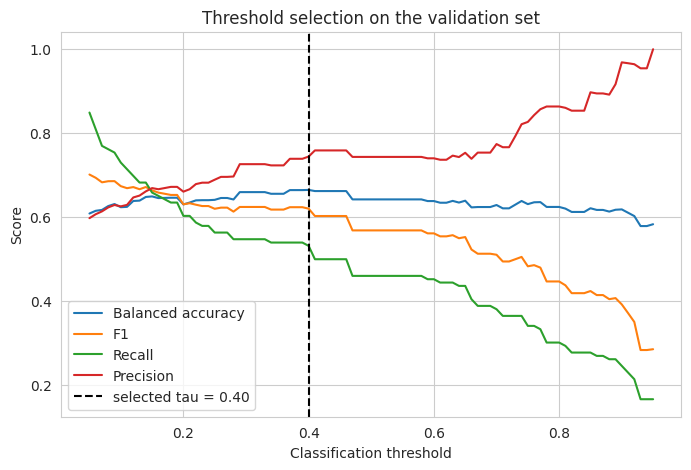

In [24]:
smote_pipe = ImbPipeline([
    ('prep', make_prep(scale=False)),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('model', XGBClassifier(eval_metric='logloss', colsample_bytree=0.8, random_state=RANDOM_STATE,
                            n_jobs=N_JOBS, **DEFAULT_PARAMS[('cls', 'XGBoost')])),
]).fit(XA_tr, yA_tr)
register_cls('XGBoost + SMOTE (sensitivity)', predict_cls(smote_pipe, XA_va), predict_cls(smote_pipe, XA_te))

rows = []
for k in ['XGBoost (default)', 'XGBoost + SMOTE (sensitivity)']:
    r = CLS[k]
    m = classification_metrics(yA_te, r['test'], r['tau']); m['Model'] = k
    rows.append(m)
print('Class weights vs SMOTE (test set, validation-selected tau):')
print(pd.DataFrame(rows).set_index('Model')[['Balanced Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'Threshold']].round(3))

# Why a fixed 0.50 threshold is not used: effect on the primary model (test set)
r = CLS['XGBoost (default)']
cmp = pd.DataFrame({f'tau = 0.50': classification_metrics(yA_te, r['test'], 0.5),
                    f"tau = {r['tau']:.2f} (validation-selected)": classification_metrics(yA_te, r['test'], r['tau'])}).T
print('\nThreshold effect, XGBoost (default), test set:')
print(cmp[['Accuracy', 'Balanced Accuracy', 'Precision', 'Recall', 'F1']].round(3))

# Threshold curve on the validation set
grid = np.arange(0.05, 0.951, 0.01)
pv = r['val']
curves = pd.DataFrame({'threshold': grid,
    'Balanced accuracy': [balanced_accuracy_score(yA_va, (pv >= t).astype(int)) for t in grid],
    'F1':                [f1_score(yA_va, (pv >= t).astype(int), zero_division=0) for t in grid],
    'Recall':            [recall_score(yA_va, (pv >= t).astype(int), zero_division=0) for t in grid],
    'Precision':         [precision_score(yA_va, (pv >= t).astype(int), zero_division=0) for t in grid]})
plt.figure(figsize=(8, 5))
for c in curves.columns[1:]: plt.plot(curves['threshold'], curves[c], label=c)
plt.axvline(r['tau'], color='k', ls='--', label=f"selected tau = {r['tau']:.2f}")
plt.xlabel('Classification threshold'); plt.ylabel('Score'); plt.title('Threshold selection on the validation set')
plt.legend(); plt.show()

## 3.10 Hyperparameter optimisation (Optuna)

Search ranges are the ones in the paper. Each trial trains on the **training countries** and is scored on the **validation countries**: PR-AUC for classification (maximise), RMSE for regression (minimise). `N_TRIALS` is set in the config cell (paper: 50–100). CatBoost with depth 10 / 1,000 iterations is the slow part: set `N_TRIALS = 10` for a dry run.

In [25]:
def sug_int(t, n, lo, hi, step=1): return t.suggest_int(n, lo, hi, step=step)

SEARCH = {
    'Random Forest': lambda t: dict(n_estimators=sug_int(t, 'n_estimators', 300, 1000, 100),
                                    max_depth=sug_int(t, 'max_depth', 5, 30),
                                    min_samples_leaf=sug_int(t, 'min_samples_leaf', 1, 20)),
    'XGBoost':       lambda t: dict(n_estimators=sug_int(t, 'n_estimators', 200, 1000, 100),
                                    max_depth=sug_int(t, 'max_depth', 3, 10),
                                    learning_rate=t.suggest_float('learning_rate', 0.01, 0.10, log=True),
                                    subsample=t.suggest_float('subsample', 0.6, 1.0)),
    'CatBoost':      lambda t: dict(iterations=sug_int(t, 'iterations', 200, 1000, 100),
                                    depth=sug_int(t, 'depth', 4, 10),
                                    learning_rate=t.suggest_float('learning_rate', 0.01, 0.10, log=True),
                                    l2_leaf_reg=t.suggest_float('l2_leaf_reg', 1, 20)),
    'SVM':           lambda t: dict(C=t.suggest_float('C', 0.1, 100, log=True),
                                    gamma=t.suggest_float('gamma', 1e-4, 1e-1, log=True)),
    'SVR':           lambda t: dict(C=t.suggest_float('C', 0.1, 100, log=True),
                                    gamma=t.suggest_float('gamma', 1e-4, 1e-1, log=True),
                                    epsilon=t.suggest_float('epsilon', 0.01, 0.50)),
}

def tune(task, name, n_trials=N_TRIALS):
    Xtr, ytr, Xva, yva = (XA_tr, yA_tr, XA_va, yA_va) if task == 'cls' else (XB_tr, yB_tr, XB_va, yB_va)
    def objective(trial):
        params = SEARCH[name](trial)
        pipe = make_pipe(name, task, params, ytr, svm_probability=False).fit(Xtr, ytr)
        if task == 'cls':
            s = pipe.decision_function(Xva) if name == 'SVM' else pipe.predict_proba(Xva)[:, 1]
            return average_precision_score(yva, s)
        return float(np.sqrt(mean_squared_error(yva, pipe.predict(Xva))))
    study = optuna.create_study(direction='maximize' if task == 'cls' else 'minimize',
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_trials)
    return study

TUNING_LOG = []
for task, names in [('cls', ['Random Forest', 'XGBoost', 'CatBoost', 'SVM']),
                    ('reg', ['Random Forest', 'XGBoost', 'CatBoost', 'SVR'])]:
    for name in names:
        study = tune(task, name)
        BEST[(task, name)] = dict(study.best_params)
        TUNING_LOG.append({'task': task, 'model': name, 'best val score': round(study.best_value, 4),
                           'metric': 'PR-AUC' if task == 'cls' else 'RMSE', 'params': dict(study.best_params)})
        print(f'{task} {name}: {study.best_value:.4f}  {study.best_params}')

# Refit the tuned models on the training countries and register them
for name in ['Random Forest', 'XGBoost', 'CatBoost', 'SVM']:
    pipe = make_pipe(name, 'cls', params_for('cls', name), yA_tr).fit(XA_tr, yA_tr)
    register_cls(f'{name} (tuned)', predict_cls(pipe, XA_va), predict_cls(pipe, XA_te))
for name in ['Random Forest', 'XGBoost', 'CatBoost', 'SVR']:
    pipe = make_pipe(name, 'reg', params_for('reg', name)).fit(XB_tr, yB_tr)
    register_reg(f'{name} (tuned)', predict_reg(pipe, XB_va), predict_reg(pipe, XB_te))
pd.DataFrame(TUNING_LOG)

cls Random Forest: 0.7773  {'n_estimators': 800, 'max_depth': 25, 'min_samples_leaf': 1}
cls XGBoost: 0.7806  {'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.012318981236462122, 'subsample': 0.8488704514267207}
cls CatBoost: 0.7731  {'iterations': 600, 'depth': 7, 'learning_rate': 0.042775368977036515, 'l2_leaf_reg': 6.114240917987483}
cls SVM: 0.7201  {'C': 1.3770760227428733, 'gamma': 0.032353502089576366}
reg Random Forest: 0.7968  {'n_estimators': 600, 'max_depth': 25, 'min_samples_leaf': 4}
reg XGBoost: 0.6976  {'n_estimators': 700, 'max_depth': 10, 'learning_rate': 0.024918634987178674, 'subsample': 0.6272278585743689}
reg CatBoost: 0.7056  {'iterations': 200, 'depth': 10, 'learning_rate': 0.01477081357571732, 'l2_leaf_reg': 19.4537272884965}
reg SVR: 0.6914  {'C': 1.7501614465005244, 'gamma': 0.00010679619402873211, 'epsilon': 0.14958458816891618}


,task,model,best val score,metric,params
0,cls,Random Forest,0.7773,PR-AUC,"{'n_estimators': 800, 'max_depth': 25, 'min_sa..."
1,cls,XGBoost,0.7806,PR-AUC,"{'n_estimators': 500, 'max_depth': 7, 'learnin..."
2,cls,CatBoost,0.7731,PR-AUC,"{'iterations': 600, 'depth': 7, 'learning_rate..."
3,cls,SVM,0.7201,PR-AUC,"{'C': 1.3770760227428733, 'gamma': 0.032353502..."
4,reg,Random Forest,0.7968,RMSE,"{'n_estimators': 600, 'max_depth': 25, 'min_sa..."
5,reg,XGBoost,0.6976,RMSE,"{'n_estimators': 700, 'max_depth': 10, 'learni..."
6,reg,CatBoost,0.7056,RMSE,"{'iterations': 200, 'depth': 10, 'learning_rat..."
7,reg,SVR,0.6914,RMSE,"{'C': 1.7501614465005244, 'gamma': 0.000106796..."


## 3.11 Spatial, temporal and external validation

**Validation 1 (grouped 70/15/15 split)** was set up above; its full results are in Section 3.12. Validations 2–4 follow. All of them reuse the tuned hyperparameters and the validation-selected thresholds τ from Validation 1. Note that the hyperparameters were tuned on the Validation-1 validation countries, so those countries are very slightly optimistic when they appear as held-out countries in Validation 2.

Compact view of Validation 1 (test countries):

In [26]:
cols = ['Balanced Accuracy', 'Recall', 'Precision', 'ROC-AUC', 'PR-AUC']
v1 = pd.DataFrame({k: classification_metrics(yA_te, r['test'], r['tau']) for k, r in CLS.items()}).T[cols].astype(float).round(3)
print('Validation 1, occurrence (test countries):'); print(v1.sort_values('PR-AUC', ascending=False))
v1r = pd.DataFrame({k: regression_metrics(yB_te, r['test']) for k, r in REG.items()}).T[['RMSE', 'MAE', 'R2']].astype(float).round(3)
print('\nValidation 1, concentration (test countries):'); print(v1r.sort_values('RMSE'))

Validation 1, occurrence (test countries):
                               Balanced Accuracy  Recall  Precision  ROC-AUC  \
Random Forest (tuned)                      0.709   0.722      0.812    0.813   
Random Forest (default)                    0.716   0.722      0.819    0.808   
XGBoost (tuned)                            0.739   0.681      0.860    0.812   
XGBoost (default)                          0.708   0.694      0.820    0.790   
CatBoost (default)                         0.642   0.840      0.733    0.772   
XGBoost + SMOTE (sensitivity)              0.732   0.590      0.895    0.769   
CatBoost (tuned)                           0.686   0.778      0.778    0.751   
SVM (tuned)                                0.607   0.924      0.704    0.735   
GAM (spline logistic)                      0.724   0.840      0.796    0.788   
SVM (default)                              0.503   0.931      0.647    0.568   
Logistic Regression                        0.430   0.785      0.608    0.469 

### Validation 2: leave-one-country-out (LOCO)
Train on every other country, test on the withheld one, for each country with at least `MIN_COUNTRY_N` rows. Per-country accuracy is dominated by that country's prevalence, so ROC-AUC / PR-AUC and balanced accuracy are the numbers to read.

LOCO, occurrence: pooled over all held-out countries
                     Balanced Accuracy  Recall  Precision  ROC-AUC  PR-AUC  \
Logistic Regression              0.526   0.931      0.597    0.652   0.746   
Random Forest                    0.651   0.822      0.688    0.727   0.787   
XGBoost                          0.646   0.827      0.683    0.725   0.785   
CatBoost                         0.622   0.861      0.661    0.716   0.772   

                     Brier  Cal. slope  
Logistic Regression  0.244       0.311  
Random Forest        0.210       0.675  
XGBoost              0.219       0.484  
CatBoost             0.229       0.379  

LOCO, concentration: pooled over all held-out countries
                    RMSE    MAE     R2  Bias (log10)  MAE (ng/L)
Linear Regression  0.614  0.508  0.231        -0.048      47.223
Random Forest      0.594  0.455  0.279         0.054      45.744
XGBoost            0.589  0.464  0.292         0.052      45.672
CatBoost           0.629  0.516  0

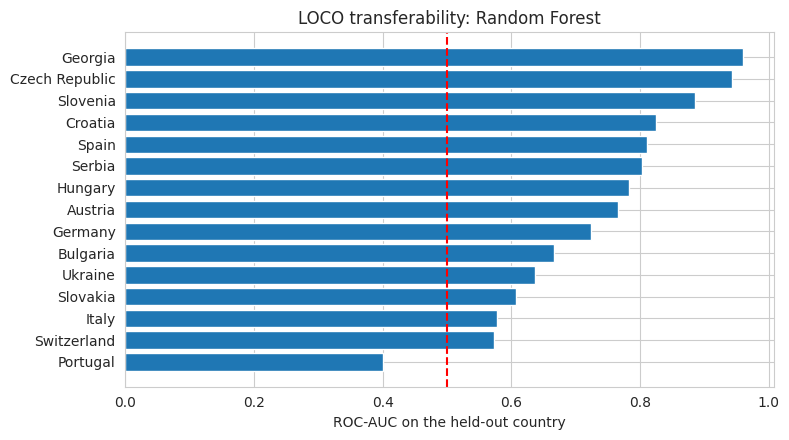

In [27]:
def leave_one_group_out_cls(models, group_series, min_n):
    counts = group_series.value_counts(); eligible = counts[counts >= min_n].index.tolist()
    oof = {m: np.full(len(df_occ), np.nan) for m in models}; rows = []
    for g in eligible:
        te = (group_series == g).values
        for m in models:
            pipe = make_pipe(m, 'cls', params_for('cls', m), y_occ.loc[~te]).fit(X_occ.loc[~te], y_occ.loc[~te])
            oof[m][te] = predict_cls(pipe, X_occ.loc[te])
            r = classification_metrics(y_occ.loc[te], oof[m][te], tau_for(m))
            rows.append({'group': g, 'model': m, 'n': int(te.sum()), 'prevalence': float(y_occ.loc[te].mean()),
                         'ROC-AUC': r['ROC-AUC'], 'PR-AUC': r['PR-AUC'],
                         'Balanced Accuracy': r['Balanced Accuracy'], 'Accuracy': r['Accuracy']})
    return pd.DataFrame(rows), oof

def leave_one_group_out_reg(models, group_series, min_n):
    counts = group_series.value_counts(); eligible = counts[counts >= min_n].index.tolist()
    oof = {m: np.full(len(df_conc), np.nan) for m in models}; rows = []
    for g in eligible:
        te = (group_series == g).values
        for m in models:
            pipe = make_pipe(m, 'reg', params_for('reg', m)).fit(X_conc.loc[~te], y_conc.loc[~te])
            oof[m][te] = predict_reg(pipe, X_conc.loc[te])
            r = regression_metrics(y_conc.loc[te], oof[m][te])
            rows.append({'group': g, 'model': m, 'n': int(te.sum()), 'RMSE': r['RMSE'], 'MAE': r['MAE'],
                         'Bias (log10)': r['Bias (log10)'], 'MAE (ng/L)': r['MAE (ng/L)']})
    return pd.DataFrame(rows), oof

def pooled_cls(oof, models):
    out = {}
    for m in models:
        ok = ~np.isnan(oof[m]); out[m] = classification_metrics(y_occ[ok], oof[m][ok], tau_for(m))
    return pd.DataFrame(out).T[['Balanced Accuracy', 'Recall', 'Precision', 'ROC-AUC', 'PR-AUC', 'Brier', 'Cal. slope']].astype(float).round(3)

def pooled_reg(oof, models):
    out = {}
    for m in models:
        ok = ~np.isnan(oof[m]); out[m] = regression_metrics(y_conc[ok], oof[m][ok])
    return pd.DataFrame(out).T[['RMSE', 'MAE', 'R2', 'Bias (log10)', 'MAE (ng/L)']].astype(float).round(3)

REG_LOCO_MODELS = ['Linear Regression', 'Random Forest', 'XGBoost', 'CatBoost']
loco_cls_df, loco_cls_oof = leave_one_group_out_cls(LOCO_MODELS, df_occ['country'], MIN_COUNTRY_N)
loco_reg_df, loco_reg_oof = leave_one_group_out_reg(REG_LOCO_MODELS, df_conc['country'], MIN_COUNTRY_N)

print('LOCO, occurrence: pooled over all held-out countries'); print(pooled_cls(loco_cls_oof, LOCO_MODELS))
print('\nLOCO, concentration: pooled over all held-out countries'); print(pooled_reg(loco_reg_oof, REG_LOCO_MODELS))

best_m = pooled_cls(loco_cls_oof, LOCO_MODELS)['PR-AUC'].idxmax()
pc = loco_cls_df[loco_cls_df['model'] == best_m].sort_values('ROC-AUC')
print(f'\nPer-country results for {best_m} (worst ROC-AUC first):'); print(pc.round(3).to_string(index=False))
plt.figure(figsize=(8, max(3, 0.3 * len(pc))))
plt.barh(pc['group'].astype(str), pc['ROC-AUC'].fillna(0.5)); plt.axvline(0.5, color='r', ls='--')
plt.xlabel('ROC-AUC on the held-out country'); plt.title(f'LOCO transferability: {best_m}'); plt.tight_layout(); plt.show()

### Validation 3: temporal validation
Earliest 70 % of the records (by `year`) for training, the next 15 % for validation (to choose τ), the most recent 15 % for testing. Years are never split across partitions. Skipped automatically if the records do not span enough years. Country mix also changes over time, so temporal and spatial effects are partly confounded.

In [28]:
def temporal_masks(years, fr=(0.70, 0.85)):
    years = pd.Series(np.asarray(years, float)); counts = years.value_counts().sort_index()
    cum = (counts.cumsum() / counts.sum())
    y_tr = cum[cum >= fr[0]].index[0]; y_va = cum[cum >= fr[1]].index[0]
    tr = (years <= y_tr).values; va = ((years > y_tr) & (years <= y_va)).values; te = (years > y_va).values
    return tr, va, te, (y_tr, y_va)

TEMPORAL_MODELS = ['Logistic Regression', 'XGBoost', 'CatBoost']
tA = temporal_masks(df_occ['year']); tB = temporal_masks(df_conc['year'])
print('Year cut-offs (train <=, val <=):', tA[3], '| rows (train/val/test) A:', [int(m.sum()) for m in tA[:3]],
      '| B:', [int(m.sum()) for m in tB[:3]])
if min(int(tA[1].sum()), int(tA[2].sum()), int(tB[1].sum()), int(tB[2].sum())) < 20:
    print('Temporal validation skipped: validation/test partitions are too small (records span too few years).')
else:
    rows = []
    for m in TEMPORAL_MODELS:
        pipe = make_pipe(m, 'cls', params_for('cls', m), y_occ[tA[0]]).fit(X_occ[tA[0]], y_occ[tA[0]])
        tau = select_threshold(y_occ[tA[1]], predict_cls(pipe, X_occ[tA[1]]), THRESHOLD_CRITERION)
        r = classification_metrics(y_occ[tA[2]], predict_cls(pipe, X_occ[tA[2]]), tau); r['Model'] = m; rows.append(r)
    print('\nTemporal validation, occurrence (most recent 15 %):')
    print(pd.DataFrame(rows).set_index('Model')[['Balanced Accuracy', 'Recall', 'Precision', 'ROC-AUC', 'PR-AUC', 'Threshold']].astype(float).round(3))
    rows = []
    for m in ['Linear Regression', 'XGBoost', 'CatBoost']:
        pipe = make_pipe(m, 'reg', params_for('reg', m)).fit(X_conc[tB[0]], y_conc[tB[0]])
        r = regression_metrics(y_conc[tB[2]], predict_reg(pipe, X_conc[tB[2]])); r['Model'] = m; rows.append(r)
    print('\nTemporal validation, concentration (most recent 15 %):')
    print(pd.DataFrame(rows).set_index('Model')[['RMSE', 'MAE', 'R2', 'Bias (log10)', 'MAE (ng/L)']].astype(float).round(3))

Year cut-offs (train <=, val <=): (np.float64(2021.0), np.float64(2022.0)) | rows (train/val/test) A: [1179, 144, 179] | B: [615, 208, 48]

Temporal validation, occurrence (most recent 15 %):
                     Balanced Accuracy  Recall  Precision  ROC-AUC  PR-AUC  \
Model                                                                        
Logistic Regression              0.562   0.208      0.476    0.524   0.353   
XGBoost                          0.525   0.188      0.333    0.503   0.330   
CatBoost                         0.541   0.250      0.353    0.472   0.306   

                     Threshold  
Model                           
Logistic Regression       0.35  
XGBoost                   0.47  
CatBoost                  0.43  

Temporal validation, concentration (most recent 15 %):
                    RMSE    MAE     R2  Bias (log10)  MAE (ng/L)
Model                                                           
Linear Regression  0.566  0.404  0.000         0.114      35.845
X

### Validation 4: water-matrix transfer
Train on the other matrices, test on the withheld one (leave-one-matrix-out, for matrices with at least `MIN_MATRIX_N` rows). The paper's case — train on river water and urban wastewater, test on municipal wastewater — is the row whose matrix name contains "municipal" (marked with ◄). Check the matrix names printed first.

In [29]:
print(df_occ['water_matrix'].value_counts())
MATRIX_MODELS = ['Logistic Regression', 'XGBoost', 'CatBoost']
mx_cls_df, mx_cls_oof = leave_one_group_out_cls(MATRIX_MODELS, df_occ['water_matrix'], MIN_MATRIX_N)
mx_cls_df['paper case'] = np.where(mx_cls_df['group'].str.contains('municipal', case=False), '◄', '')
print('\nMatrix transfer, occurrence (train on other matrices, test on the held-out matrix):')
print(mx_cls_df.round(3).to_string(index=False))

mx_reg_df, _ = leave_one_group_out_reg(['Linear Regression', 'XGBoost', 'CatBoost'], df_conc['water_matrix'], MIN_MATRIX_N)
mx_reg_df['paper case'] = np.where(mx_reg_df['group'].str.contains('municipal', case=False), '◄', '')
print('\nMatrix transfer, concentration:'); print(mx_reg_df.round(3).to_string(index=False))

water_matrix
river/lake      1274
municipal_ww     197
groundwater       31
Name: count, dtype: int64

Matrix transfer, occurrence (train on other matrices, test on the held-out matrix):
       group               model    n  prevalence  ROC-AUC  PR-AUC  Balanced Accuracy  Accuracy paper case
  river/lake Logistic Regression 1274       0.526    0.620   0.613              0.585     0.594           
  river/lake             XGBoost 1274       0.526    0.527   0.535              0.524     0.546           
  river/lake            CatBoost 1274       0.526    0.553   0.557              0.500     0.526           
municipal_ww Logistic Regression  197       0.934    0.668   0.966              0.617     0.751          ◄
municipal_ww             XGBoost  197       0.934    0.594   0.948              0.539     0.472          ◄
municipal_ww            CatBoost  197       0.934    0.615   0.952              0.560     0.513          ◄

Matrix transfer, concentration:
       group             model 

## 3.12 Performance metrics

**Occurrence:** accuracy, precision, recall, F1, ROC-AUC, PR-AUC, balanced accuracy, Brier score, calibration slope (ideal = 1) and calibration plot. **Concentration:** RMSE, MAE, R², prediction bias, and the same errors after back-transforming to ng/L. Thresholds τ were chosen on the validation countries and applied unchanged to the test countries.

In [30]:
def cls_table(split):
    y = yA_va if split == 'val' else yA_te
    t = pd.DataFrame({k: classification_metrics(y, r[split], r['tau']) for k, r in CLS.items()}).T
    return t.astype({c: float for c in t.columns if c not in ('TN', 'FP', 'FN', 'TP')}).round(3)

def reg_table(split):
    y = yB_va if split == 'val' else yB_te
    return pd.DataFrame({k: regression_metrics(y, r[split]) for k, r in REG.items()}).T.astype(float).round(3)

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('=== OCCURRENCE, test countries ===');  display(cls_table('test').sort_values('PR-AUC', ascending=False))
print('=== CONCENTRATION, test countries (log10 and ng/L) ==='); display(reg_table('test').sort_values('RMSE'))

=== OCCURRENCE, test countries ===


,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,Cal. slope,ECE,Threshold,TN,FP,FN,TP
Random Forest (tuned),0.713,0.709,0.812,0.722,0.765,0.813,0.912,0.174,1.481,0.131,0.470,55.0,24.0,40.0,104.0
Random Forest (default),0.717,0.716,0.819,0.722,0.768,0.808,0.908,0.184,1.330,0.151,0.460,56.0,23.0,40.0,104.0
XGBoost (tuned),0.722,0.739,0.860,0.681,0.760,0.812,0.905,0.189,0.877,0.144,0.380,63.0,16.0,46.0,98.0
XGBoost (default),0.704,0.708,0.820,0.694,0.752,0.790,0.887,0.212,0.673,0.184,0.400,57.0,22.0,44.0,100.0
CatBoost (default),0.700,0.642,0.733,0.840,0.783,0.772,0.884,0.215,0.589,0.199,0.225,35.0,44.0,23.0,121.0
XGBoost + SMOTE (sensitivity),0.691,0.732,0.895,0.590,0.711,0.769,0.877,0.225,0.576,0.182,0.490,69.0,10.0,59.0,85.0
CatBoost (tuned),0.713,0.686,0.778,0.778,0.778,0.751,0.866,0.224,0.564,0.180,0.290,47.0,32.0,32.0,112.0
SVM (tuned),0.700,0.607,0.704,0.924,0.799,0.735,0.844,0.195,0.776,0.090,0.330,23.0,56.0,11.0,133.0
GAM (spline logistic),0.758,0.724,0.796,0.840,0.818,0.788,0.830,0.184,0.558,0.116,0.380,48.0,31.0,23.0,121.0
SVM (default),0.628,0.503,0.647,0.931,0.764,0.568,0.749,0.245,0.297,0.147,0.320,6.0,73.0,10.0,134.0


=== CONCENTRATION, test countries (log10 and ng/L) ===


,RMSE,MAE,R2,Bias (log10),RMSE (ng/L),MAE (ng/L),Bias (ng/L),Median abs. error (ng/L)
Linear Regression,0.580,0.464,0.460,0.090,126.250,46.558,-27.849,4.815
Mixed-effects (country RE),0.580,0.464,0.460,0.090,126.250,46.558,-27.849,4.815
SVR (default),0.602,0.442,0.417,0.142,122.189,43.548,-27.337,5.863
CatBoost (default),0.606,0.495,0.411,0.208,122.225,44.443,-29.658,8.125
CatBoost (tuned),0.671,0.588,0.278,0.224,127.050,45.828,-34.160,8.755
XGBoost (tuned),0.675,0.556,0.267,0.319,119.013,43.902,-24.581,14.798
Random Forest (default),0.683,0.537,0.250,0.352,114.670,42.515,-17.814,14.635
Random Forest (tuned),0.689,0.539,0.237,0.353,115.205,42.729,-17.670,15.046
XGBoost (default),0.693,0.551,0.229,0.345,118.462,43.475,-16.399,13.914
Tobit (E[y | quantified]),0.775,0.674,0.036,0.129,126.053,50.363,-25.432,10.301


## 3.13 Ensemble methods (hard/soft voting, simple/weighted averaging, stacking, blending)

Added after 3.12; no earlier cell is modified. Base models are the Stage 1 classifiers in `CLS` and the Stage 2 regressors in `REG` (tuned versions where they exist), so no base model is redefined. Ensemble results go into new dictionaries `ENS_CLS` / `ENS_REG`, leaving `CLS` and `REG` unchanged.

| Method | Idea | Applied to |
|---|---|---|
| Hard Voting | Majority vote of predicted classes | Stage 1 |
| Soft Voting | Average predicted probabilities | Stage 1 |
| Simple Averaging | Average numerical predictions | Stage 2 |
| Weighted Averaging | Weights from validation performance | Both |
| Stacking | Meta-model on out-of-fold base predictions (country-grouped folds inside the training countries) | Both |
| Blending | Meta-model on the validation countries' predictions (separate holdout) | Both |

Leakage rules: base models only see training countries; weights and blending meta-models use validation countries only; stacking meta-models use out-of-fold predictions on training countries; the test countries are used only for the final scores.


In [31]:
# ---- 3.13a  Base models + shared helpers -----------------------------------------
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold

_CLS_OK = {'Logistic Regression', 'GAM (spline logistic)', 'Random Forest', 'XGBoost', 'CatBoost', 'SVM', 'EBM'}
_REG_OK = {'Linear Regression', 'Random Forest', 'XGBoost', 'CatBoost', 'SVR'}
def _strip(label): return re.sub(r' \((default|tuned)\)$', '', label)
def _pick_base(registry, ok):
    # prefer the tuned version of a model; skip SMOTE sensitivity, Tobit, mixed effects (not rebuilt by make_pipe)
    return [k for k in registry
            if _strip(k) in ok and not (k.endswith('(default)') and k.replace('(default)', '(tuned)') in registry)]
ENS_CLS_BASE = _pick_base(CLS, _CLS_OK)      # edit these lists to change the ensemble members
ENS_REG_BASE = _pick_base(REG, _REG_OK)
print('Stage 1 base models:', ENS_CLS_BASE); print('Stage 2 base models:', ENS_REG_BASE)

ENS_CLS, ENS_REG, ENS_INFO = {}, {}, {}

def _label_to_pipe(label, task, y_train=None):
    base = _strip(label)
    params = DEFAULT_PARAMS.get((task, base), {}) if label.endswith('(default)') else params_for(task, base)
    return make_pipe(base, task, params, y_train)

def _groups_clean(g):
    g = pd.Series(np.asarray(g, dtype=object)).copy()
    miss = g.isna() | (g.astype(str).str.strip() == '')
    g[miss] = [f'__missing_{i}' for i in np.where(miss)[0]]          # each unlabeled row is its own group
    return g.values

def oof_predictions(task, labels, X, y, groups, n_splits_max=5):
    """Out-of-fold predictions on the training countries, country-grouped. Base models are refit in every fold."""
    y = np.asarray(y); g = _groups_clean(groups); X = X.reset_index(drop=True)
    n_splits = min(n_splits_max, len(pd.unique(g)))
    assert n_splits >= 2, 'need at least 2 training countries for stacking'
    if task == 'cls':
        best = None
        for s in range(RANDOM_STATE, RANDOM_STATE + 50):
            f = list(StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=s).split(X, y.astype(int), g))
            bad = sum(len(np.unique(y[tr])) < 2 for tr, _ in f)
            if best is None or bad < best[0]: best = (bad, f)
            if bad == 0: break
        folds = best[1]
    else:
        folds = list(GroupKFold(n_splits=n_splits).split(X, y, g))
    for tr, va in folds: assert not (set(g[tr]) & set(g[va])), 'country overlap between folds'
    oof = pd.DataFrame(np.nan, index=range(len(y)), columns=labels)
    for i, (tr, va) in enumerate(folds):
        if task == 'cls' and len(np.unique(y[tr])) < 2:
            print(f'  fold {i}: single-class training fold -> skipped'); continue
        for lab in labels:
            try:
                est = _label_to_pipe(lab, task, y[tr]).fit(X.iloc[tr], y[tr])
                oof.loc[va, lab] = (predict_cls if task == 'cls' else predict_reg)(est, X.iloc[va])
            except Exception as e:
                print(f'  fold {i} [{lab}]: {type(e).__name__}: {e} -> NaN')
    return oof

def cls_metrics_row(y, p, tau):
    m = classification_metrics(y, p, tau)
    m['Specificity'] = m['TN'] / (m['TN'] + m['FP']) if (m['TN'] + m['FP']) else np.nan
    return m
def reg_P(labels, split): return np.column_stack([REG[k][split] for k in labels])
def cls_P(labels, split): return np.column_stack([CLS[k][split] for k in labels])
def norm_w(w): w = np.clip(np.asarray(w, float), 0, None); return w / w.sum() if w.sum() > 0 else np.full(len(w), 1 / len(w))


Stage 1 base models: ['Logistic Regression', 'GAM (spline logistic)', 'Random Forest (tuned)', 'XGBoost (tuned)', 'CatBoost (tuned)', 'SVM (tuned)']
Stage 2 base models: ['Linear Regression', 'Random Forest (tuned)', 'XGBoost (tuned)', 'CatBoost (tuned)', 'SVR (tuned)']


In [32]:
# ---- 3.13b  Stage 1 ensembles (occurrence) ----------------------------------------
B = ENS_CLS_BASE
Pva, Pte = cls_P(B, 'val'), cls_P(B, 'test')
grp_va = _groups_clean(df_occ.loc[mask_A['val'], 'country'])

def _reg_cls(name, pv, pt, tau=None, tau_data=None):
    """tau_data = (y, p) pairs on which tau is chosen. Must be data the meta-model did NOT fit on."""
    pv, pt = np.asarray(pv, float), np.asarray(pt, float)
    ty, tp = tau_data if tau_data is not None else (np.asarray(yA_va), pv)
    ENS_CLS[name] = {'val': pv, 'test': pt, 'tau_data': (np.asarray(ty), np.asarray(tp)),
                     'tau': select_threshold(ty, tp, THRESHOLD_CRITERION) if tau is None else tau}

def _logit(p, eps=1e-4):
    p = np.clip(np.asarray(p, float), eps, 1 - eps); return np.log(p / (1 - p))

def fit_nonneg_logit(Z, y, lam=0.01):
    """Logistic meta-model with NON-NEGATIVE weights (one per base model) and a free intercept.
    Class-balanced. Negative weights on correlated base models are what made the old stacker unstable."""
    Z = np.asarray(Z, float); y = np.asarray(y, float); n, k = Z.shape
    sw = np.where(y == 1, 0.5 / max(y.mean(), 1e-9), 0.5 / max(1 - y.mean(), 1e-9))
    def f(th):
        s = th[0] + Z @ th[1:]
        loss = np.mean(sw * (np.logaddexp(0, s) - y * s)) + 0.5 * lam * np.sum(th[1:] ** 2)
        g = sw * (1 / (1 + np.exp(-s)) - y) / n
        return loss, np.r_[g.sum(), Z.T @ g + lam * th[1:]]
    res = optimize.minimize(f, np.r_[0.0, np.full(k, 1.0 / k)], jac=True, method='L-BFGS-B',
                            bounds=[(None, None)] + [(0, None)] * k)
    return res.x
def predict_nonneg_logit(th, Z): return 1 / (1 + np.exp(-(th[0] + np.asarray(Z, float) @ th[1:])))

# Soft voting: mean probability, tau selected on validation
_reg_cls('Soft Voting', Pva.mean(1), Pte.mean(1))

# Hard voting: each model votes with its own validation-selected tau; ties go to the soft-vote decision
def _hard(P, taus, soft_p, soft_tau):
    share = (P >= np.asarray(taus)).mean(1)
    return np.where(share == 0.5, 0.5 + np.where(soft_p >= soft_tau, 1e-6, -1e-6), share)   # classify with threshold 0.5
taus = [CLS[k]['tau'] for k in B]
_reg_cls('Hard Voting', _hard(Pva, taus, ENS_CLS['Soft Voting']['val'], ENS_CLS['Soft Voting']['tau']),
         _hard(Pte, taus, ENS_CLS['Soft Voting']['test'], ENS_CLS['Soft Voting']['tau']), tau=0.5)

# Weighted averaging. FIX: weights = validation PR-AUC *lift over prevalence*. Raw PR-AUC differs little between
# models (0.157-0.175 after normalising), which made this method identical to soft voting.
prev_va = float(np.mean(yA_va))
lift = [average_precision_score(yA_va, CLS[k]['val']) - prev_va for k in B]
w_cls = norm_w(lift)
_reg_cls('Weighted Averaging', Pva @ w_cls, Pte @ w_cls)
ENS_INFO['cls_weights'] = pd.Series(w_cls, index=B)

# Stacking. FIXES: (1) non-negative meta-weights on logit(p), (2) base models that are no better than chance on the
# out-of-fold predictions are left out, (3) tau is chosen on the VALIDATION countries like every other method
# (it used to be chosen on the same out-of-fold rows the meta-model was fitted on, which gave tau a value that did
# not transfer: recall 0.29, F1 0.41, ROC-AUC 0.51 on the test countries).
oofA = oof_predictions('cls', B, XA_tr, yA_tr, df_occ.loc[mask_A['train'], 'country'])
ok = oofA.notna().all(axis=1).values
y_oof = np.asarray(yA_tr)[ok]
if ok.sum() > 0 and len(np.unique(y_oof)) == 2:
    good = [k for k in B if roc_auc_score(y_oof, oofA.loc[ok, k]) > 0.5]
    if set(B) - set(good): print('Stacking: dropped base models with out-of-fold ROC-AUC <= 0.5:', sorted(set(B) - set(good)))
    if good:
        gi = [B.index(k) for k in good]
        th = fit_nonneg_logit(_logit(oofA.loc[ok, good].values), y_oof)
        _reg_cls('Stacking', predict_nonneg_logit(th, _logit(Pva[:, gi])), predict_nonneg_logit(th, _logit(Pte[:, gi])))
        ENS_INFO['cls_stack_coef'] = pd.Series(th[1:], index=good)
else: print('Stacking skipped: not enough valid out-of-fold rows / only one class')

# Blending. FIX: the meta-model is fitted on the validation countries, so its validation predictions are in-sample and
# a tau picked on them is optimistic. tau is now picked on country-grouped cross-validated blend predictions.
if len(np.unique(yA_va)) == 2:
    yv = np.asarray(yA_va).astype(int)
    th_b = fit_nonneg_logit(_logit(Pva), yv)
    pv_b, pt_b = predict_nonneg_logit(th_b, _logit(Pva)), predict_nonneg_logit(th_b, _logit(Pte))
    oof_b = np.full(len(yv), np.nan)
    for tr, te in GroupKFold(n_splits=min(4, len(np.unique(grp_va)))).split(Pva, yv, grp_va):
        if len(np.unique(yv[tr])) < 2: continue
        oof_b[te] = predict_nonneg_logit(fit_nonneg_logit(_logit(Pva[tr]), yv[tr]), _logit(Pva[te]))
    m = ~np.isnan(oof_b)
    if m.sum() > 20 and len(np.unique(yv[m])) == 2:
        _reg_cls('Blending', pv_b, pt_b, tau_data=(yv[m], oof_b[m]))
    else:
        print('Blending: grouped CV not possible, tau chosen in-sample (optimistic)'); _reg_cls('Blending', pv_b, pt_b)
    ENS_INFO['cls_blend_coef'] = pd.Series(th_b[1:], index=B)
else: print('Blending skipped: single-class validation set')

print('Weighted-averaging weights (validation PR-AUC lift over prevalence):'); display(ENS_INFO['cls_weights'].round(3).to_frame('weight'))
for k in ('cls_stack_coef', 'cls_blend_coef'):
    if k in ENS_INFO: print(k, 'meta-model weights (non-negative):'); display(ENS_INFO[k].round(3).to_frame('weight'))

rows = {k: cls_metrics_row(yA_te, r['test'], r['tau']) for k, r in ENS_CLS.items()}
rows.update({f'[base] {k}': cls_metrics_row(yA_te, CLS[k]['test'], CLS[k]['tau']) for k in B})
STAGE1_ENS_TABLE = pd.DataFrame(rows).T
cols = ['TN', 'FP', 'FN', 'TP', 'Accuracy', 'Balanced Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC-AUC', 'PR-AUC', 'Brier']
print('=== Stage 1 ensembles vs base models, test countries (tau selected without test data) ===')
display(STAGE1_ENS_TABLE[cols].astype({c: float for c in cols[4:]}).round(3).sort_values('PR-AUC', ascending=False))

Weighted-averaging weights (validation PR-AUC lift over prevalence):


,weight
Logistic Regression,0.140
GAM (spline logistic),0.134
Random Forest (tuned),0.192
XGBoost (tuned),0.195
CatBoost (tuned),0.189
SVM (tuned),0.149


cls_stack_coef meta-model weights (non-negative):


,weight
Logistic Regression,0.279
GAM (spline logistic),0.164
Random Forest (tuned),0.000
XGBoost (tuned),0.000
CatBoost (tuned),0.000
SVM (tuned),0.000


cls_blend_coef meta-model weights (non-negative):


,weight
Logistic Regression,0.000
GAM (spline logistic),0.070
Random Forest (tuned),0.509
XGBoost (tuned),0.063
CatBoost (tuned),0.000
SVM (tuned),0.000


=== Stage 1 ensembles vs base models, test countries (tau selected without test data) ===


,TN,FP,FN,TP,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,Brier
Blending,18.0,61.0,9.0,135.0,0.686,0.583,0.689,0.938,0.228,0.794,0.832,0.920,0.169
[base] Random Forest (tuned),55.0,24.0,40.0,104.0,0.713,0.709,0.812,0.722,0.696,0.765,0.813,0.912,0.174
[base] XGBoost (tuned),63.0,16.0,46.0,98.0,0.722,0.739,0.860,0.681,0.797,0.760,0.812,0.905,0.189
Soft Voting,45.0,34.0,31.0,113.0,0.709,0.677,0.769,0.785,0.570,0.777,0.801,0.903,0.185
Weighted Averaging,13.0,66.0,9.0,135.0,0.664,0.551,0.672,0.938,0.165,0.783,0.801,0.903,0.184
[base] CatBoost (tuned),47.0,32.0,32.0,112.0,0.713,0.686,0.778,0.778,0.595,0.778,0.751,0.866,0.224
Hard Voting,41.0,38.0,26.0,118.0,0.713,0.669,0.756,0.819,0.519,0.787,0.778,0.847,0.191
[base] SVM (tuned),23.0,56.0,11.0,133.0,0.700,0.607,0.704,0.924,0.291,0.799,0.735,0.844,0.195
[base] GAM (spline logistic),48.0,31.0,23.0,121.0,0.758,0.724,0.796,0.840,0.608,0.818,0.788,0.830,0.184
Stacking,37.0,42.0,51.0,93.0,0.583,0.557,0.689,0.646,0.468,0.667,0.615,0.769,0.246


In [33]:
# ---- 3.13c  Stage 2 ensembles (conditional concentration; existing Stage 2 cells untouched) ----
R = ENS_REG_BASE
Rva, Rte = reg_P(R, 'val'), reg_P(R, 'test')
def _reg_reg(name, pv, pt): ENS_REG[name] = {'val': np.clip(pv, 0, None), 'test': np.clip(pt, 0, None)}

_reg_reg('Simple Averaging', Rva.mean(1), Rte.mean(1))

w_reg = norm_w([1 / max(np.sqrt(mean_squared_error(yB_va, REG[k]['val'])), 1e-9) for k in R])   # inverse validation RMSE
_reg_reg('Weighted Averaging', Rva @ w_reg, Rte @ w_reg)
ENS_INFO['reg_weights'] = pd.Series(w_reg, index=R)

# Stacking: non-negative linear meta-model on country-grouped out-of-fold training predictions
oofB = oof_predictions('reg', R, XB_tr, yB_tr, df_conc.loc[mask_B['train'], 'country'])
okB = oofB.notna().all(1).values
if okB.sum() > len(R):
    meta_r = LinearRegression(positive=True).fit(oofB.values[okB], np.asarray(yB_tr)[okB])
    _reg_reg('Stacking', meta_r.predict(Rva), meta_r.predict(Rte))
    ENS_INFO['reg_stack_coef'] = pd.Series(meta_r.coef_, index=R)
else: print('Stage 2 stacking skipped: too few valid out-of-fold rows')

# Blending: non-negative linear meta-model fitted on the validation countries
if len(yB_va) > len(R):
    meta_rb = LinearRegression(positive=True).fit(Rva, yB_va)
    _reg_reg('Blending', meta_rb.predict(Rva), meta_rb.predict(Rte))
    ENS_INFO['reg_blend_coef'] = pd.Series(meta_rb.coef_, index=R)
else: print('Stage 2 blending skipped: too few validation rows')

print('Weighted-averaging weights (1 / validation RMSE):'); display(ENS_INFO['reg_weights'].round(3).to_frame('weight'))
for k in ('reg_stack_coef', 'reg_blend_coef'):
    if k in ENS_INFO: print(k, 'meta-model coefficients:'); display(ENS_INFO[k].round(3).to_frame('coef'))

rows = {k: regression_metrics(yB_te, r['test']) for k, r in ENS_REG.items()}
rows.update({f'[base] {k}': regression_metrics(yB_te, REG[k]['test']) for k in R})
STAGE2_ENS_TABLE = pd.DataFrame(rows).T.astype(float).round(3).sort_values('RMSE')
print('=== Stage 2 ensembles vs base models, test countries (log10 and ng/L) ==='); display(STAGE2_ENS_TABLE)


Weighted-averaging weights (1 / validation RMSE):


,weight
Linear Regression,0.222
Random Forest (tuned),0.176
XGBoost (tuned),0.201
CatBoost (tuned),0.199
SVR (tuned),0.203


reg_stack_coef meta-model coefficients:


,coef
Linear Regression,0.274
Random Forest (tuned),0.187
XGBoost (tuned),0.016
CatBoost (tuned),0.000
SVR (tuned),0.000


reg_blend_coef meta-model coefficients:


,coef
Linear Regression,0.567
Random Forest (tuned),0.000
XGBoost (tuned),0.315
CatBoost (tuned),0.000
SVR (tuned),0.000


=== Stage 2 ensembles vs base models, test countries (log10 and ng/L) ===


,RMSE,MAE,R2,Bias (log10),RMSE (ng/L),MAE (ng/L),Bias (ng/L),Median abs. error (ng/L)
Blending,0.578,0.488,0.463,0.154,123.080,43.591,-32.443,6.183
[base] Linear Regression,0.580,0.464,0.460,0.090,126.250,46.558,-27.849,4.815
Weighted Averaging,0.631,0.544,0.361,0.244,123.274,44.065,-31.313,9.032
Simple Averaging,0.633,0.546,0.355,0.250,123.146,44.064,-31.060,9.251
[base] CatBoost (tuned),0.671,0.588,0.278,0.224,127.050,45.828,-34.160,8.755
Stacking,0.675,0.591,0.268,0.216,126.882,45.560,-34.595,8.540
[base] XGBoost (tuned),0.675,0.556,0.267,0.319,119.013,43.902,-24.581,14.798
[base] Random Forest (tuned),0.689,0.539,0.237,0.353,115.205,42.729,-17.670,15.046
[base] SVR (tuned),0.779,0.693,0.025,0.265,129.009,48.863,-34.133,11.539


In [34]:
# ---- 3.13d  Best ensemble vs best single base model --------------------------------
t1 = STAGE1_ENS_TABLE[['Balanced Accuracy', 'F1', 'ROC-AUC', 'PR-AUC']].astype(float)
ens1 = t1[~t1.index.str.startswith('[base]')]; base1 = t1[t1.index.str.startswith('[base]')]
print('Stage 1 (PR-AUC): best ensemble =', ens1['PR-AUC'].idxmax(), round(ens1['PR-AUC'].max(), 3),
      '| best base =', base1['PR-AUC'].idxmax(), round(base1['PR-AUC'].max(), 3))
t2 = STAGE2_ENS_TABLE
ens2 = t2[~t2.index.str.startswith('[base]')]; base2 = t2[t2.index.str.startswith('[base]')]
print('Stage 2 (RMSE):   best ensemble =', ens2['RMSE'].idxmin(), round(ens2['RMSE'].min(), 3),
      '| best base =', base2['RMSE'].idxmin(), round(base2['RMSE'].min(), 3))
# Note: weights, tau and blending meta-models use the validation countries, stacking uses out-of-fold training predictions;
# the test countries are only scored. Differences between methods on a handful of test countries may be within noise.


Stage 1 (PR-AUC): best ensemble = Blending 0.92 | best base = [base] Random Forest (tuned) 0.912
Stage 2 (RMSE):   best ensemble = Blending 0.578 | best base = [base] Linear Regression 0.58


### 3.13f  F1-score comparison of all ensemble methods
Stage 1 (occurrence) is the only classification stage, so F1 is compared there. The table shows F1 at the validation-selected threshold (as in the tables above) and at the F1-optimal threshold, with a bootstrap interval. Stage 2 ensembles are regressors (RMSE / MAE / R²).

Test prevalence = 0.646; always-predict-positive F1 = 0.785


,Type,tau (sel),Precision,Recall,F1 @ tau(sel),F1 95% CI,tau (F1),F1 @ tau(F1)
Method,,,,,,,,
[base] GAM (spline logistic),Base model,0.38,0.796,0.840,0.818,"[0.766, 0.864]",0.075,0.799
[base] SVM (tuned),Base model,0.33,0.704,0.924,0.799,"[0.750, 0.842]",0.300,0.800
Blending,Ensemble,0.46,0.689,0.938,0.794,"[0.749, 0.840]",0.080,0.787
Hard Voting,Ensemble,0.50,0.756,0.819,0.787,"[0.737, 0.833]",0.500,0.787
Weighted Averaging,Ensemble,0.25,0.672,0.938,0.783,"[0.736, 0.825]",0.090,0.787
[base] CatBoost (tuned),Base model,0.29,0.778,0.778,0.778,"[0.722, 0.825]",0.050,0.793
Soft Voting,Ensemble,0.43,0.769,0.785,0.777,"[0.723, 0.826]",0.090,0.787
[base] Random Forest (tuned),Base model,0.47,0.812,0.722,0.765,"[0.706, 0.815]",0.140,0.789
[base] XGBoost (tuned),Base model,0.38,0.860,0.681,0.760,"[0.699, 0.813]",0.050,0.789



Best ensemble by F1: Blending (0.794) | best base model: [base] GAM (spline logistic) (0.818)


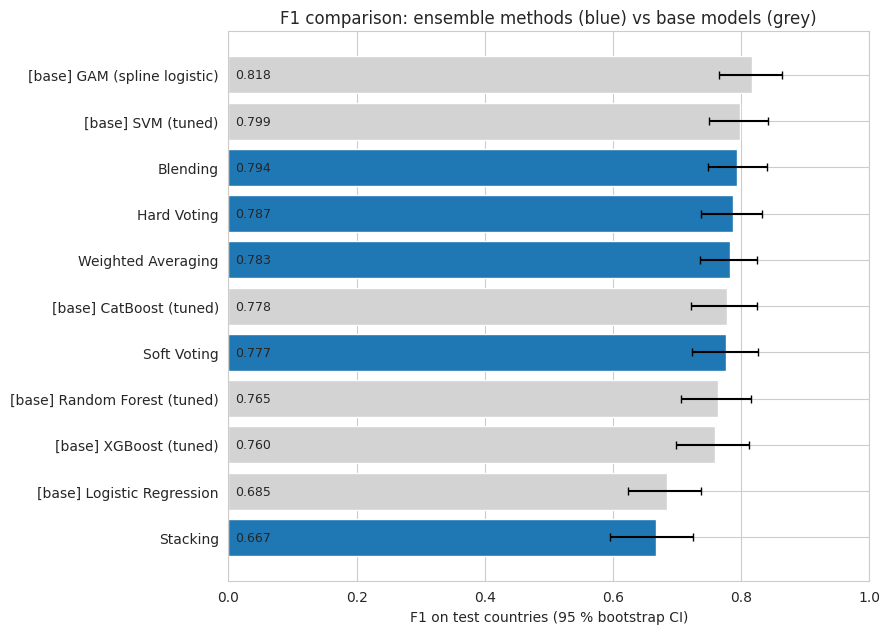

Stage 2 (concentration) ensembles are regressors: F1 is not defined for them; see RMSE / MAE / R2 in 3.13c.


In [35]:
# ---- 3.13f  F1-score comparison of all Stage 1 ensemble methods (test countries) -------------------
# F1 depends on the threshold, so two versions are shown:
#   F1 @ tau(sel)  : tau chosen on the validation countries with THRESHOLD_CRITERION (what the tables above use)
#   F1 @ tau(F1)   : tau chosen on the validation countries to maximise F1 (Hard Voting keeps its 0.5 majority rule)
# The 95 % interval is a row-level bootstrap of the test countries. It ignores clustering by country, so it is optimistic.
y_te = np.asarray(yA_te).astype(int)
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = rng.integers(0, len(y_te), size=(1000, len(y_te)))

def f1_ci(pred):
    s = [f1_score(y_te[i], pred[i], zero_division=0) for i in boot_idx]
    return np.percentile(s, [2.5, 97.5])

members = {**{k: ('Ensemble', r) for k, r in ENS_CLS.items()},
           **{f'[base] {k}': ('Base model', CLS[k]) for k in ENS_CLS_BASE}}
rows = []
for name, (kind, r) in members.items():
    pred = (r['test'] >= r['tau']).astype(int)
    ty, tp = r.get('tau_data', (np.asarray(yA_va), r['val']))
    tau_f1 = 0.5 if name == 'Hard Voting' else select_threshold(ty, tp, 'f1')
    pred_f1 = (r['test'] >= tau_f1).astype(int)
    lo, hi = f1_ci(pred)
    rows.append({'Method': name, 'Type': kind, 'tau (sel)': r['tau'], 'Precision': precision_score(y_te, pred, zero_division=0),
                 'Recall': recall_score(y_te, pred, zero_division=0), 'F1 @ tau(sel)': f1_score(y_te, pred, zero_division=0),
                 'F1 95% CI': f'[{lo:.3f}, {hi:.3f}]', 'tau (F1)': tau_f1, 'F1 @ tau(F1)': f1_score(y_te, pred_f1, zero_division=0)})
F1_TABLE = pd.DataFrame(rows).set_index('Method').sort_values('F1 @ tau(sel)', ascending=False)
num = ['tau (sel)', 'Precision', 'Recall', 'F1 @ tau(sel)', 'tau (F1)', 'F1 @ tau(F1)']
F1_TABLE[num] = F1_TABLE[num].astype(float).round(3)
print(f'Test prevalence = {y_te.mean():.3f}; always-predict-positive F1 = {f1_score(y_te, np.ones_like(y_te)):.3f}')
display(F1_TABLE)

ens = F1_TABLE[F1_TABLE['Type'] == 'Ensemble']; base = F1_TABLE[F1_TABLE['Type'] == 'Base model']
print(f"\nBest ensemble by F1: {ens['F1 @ tau(sel)'].idxmax()} ({ens['F1 @ tau(sel)'].max():.3f}) | "
      f"best base model: {base['F1 @ tau(sel)'].idxmax()} ({base['F1 @ tau(sel)'].max():.3f})")

fig, ax = plt.subplots(figsize=(9, 0.45 * len(F1_TABLE) + 1.5))
plot_df = F1_TABLE.iloc[::-1]
lo_hi = np.array([[float(s.strip('[]').split(',')[0]), float(s.strip('[]').split(',')[1])] for s in plot_df['F1 95% CI']])
err = np.vstack([plot_df['F1 @ tau(sel)'].values - lo_hi[:, 0], lo_hi[:, 1] - plot_df['F1 @ tau(sel)'].values])
colors = ['tab:blue' if t == 'Ensemble' else 'lightgray' for t in plot_df['Type']]
ax.barh(plot_df.index, plot_df['F1 @ tau(sel)'], xerr=err, color=colors, capsize=3)
for i, v in enumerate(plot_df['F1 @ tau(sel)']): ax.text(0.01, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlabel('F1 on test countries (95 % bootstrap CI)'); ax.set_xlim(0, 1)
ax.set_title('F1 comparison: ensemble methods (blue) vs base models (grey)'); plt.tight_layout(); plt.show()
print('Stage 2 (concentration) ensembles are regressors: F1 is not defined for them; see RMSE / MAE / R2 in 3.13c.')

In [36]:
# ---- 3.13e  Harness check: every method present, no degenerate base model
expected_cls = {'Hard Voting','Soft Voting','Weighted Averaging','Stacking','Blending'}
expected_reg = {'Simple Averaging','Weighted Averaging','Stacking','Blending'}
print('Stage 1 missing:', sorted(expected_cls - set(ENS_CLS)) or 'none')
print('Stage 2 missing:', sorted(expected_reg - set(ENS_REG)) or 'none')
for k in ENS_CLS_BASE: assert np.nanstd(CLS[k]['test']) > 1e-6, f'{k}: constant predictions'

for k, r in ENS_CLS.items():
    auc = roc_auc_score(yA_te, r['test'])
    if k != 'Hard Voting' and auc < 0.6: print(f'WARNING: {k} test ROC-AUC = {auc:.3f} (near chance) - check the meta-model')

Stage 1 missing: none
Stage 2 missing: none


# SMX: uncertainty quantification, SHAP explainability and monitoring risk classes

Added after the ensemble section; **no earlier cell is modified**. These cells implement the paper's calibrated probabilities, 90 % conformal
intervals, SHAP analysis and four-class risk scheme (paper sections 3.13-3.15; they are numbered separately from this notebook's own section 3.13, which is the ensemble section).

Run order: all cells above first (*Run All*), then the three cells below. Outputs go to `/kaggle/working/smx_uq_outputs/` (an existing folder is moved to `..._backup_<timestamp>`, never overwritten).

* Train countries fit the models; validation countries fit the calibrator, the conformal quantile and the risk thresholds; test countries are only scored.
* Final classifier/regressor = best **tuned single tree model** by validation PR-AUC / RMSE (so TreeSHAP is exact).
* Concentration intervals are on `log10(C+1)`, conditional on the sample being quantified.

In [ ]:
!pip install -q shap folium


In [ ]:
# Writes the smx_uq package next to the notebook (self-contained; no upload needed).
import os
os.makedirs('smx_uq', exist_ok=True)
open('smx_uq/__init__.py', 'w').write('from . import calibration, intervals, risk, ood, explain, maps   # noqa: F401\nfrom .pipeline import run_smx_uq, RunConfig                      # noqa: F401\n')
open('smx_uq/calibration.py', 'w').write('"""Stage-1 probability calibration (paper s3.13.1). SMX only.\n\nLeakage rules enforced by construction:\n  * calibrators are fitted ONLY on arrays passed in by the caller (validation countries);\n  * method selection uses country-grouped cross-fitting *inside* the validation set;\n  * nothing here ever receives test labels except `calibration_report`, which only scores.\n"""\nfrom __future__ import annotations\nimport numpy as np\nfrom sklearn.isotonic import IsotonicRegression\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (average_precision_score, brier_score_loss, log_loss,\n                             roc_auc_score)\nfrom sklearn.model_selection import GroupKFold\n\nEPS = 1e-6\n\n\ndef _logit(p, eps=EPS):\n    p = np.clip(np.asarray(p, float), eps, 1 - eps)\n    return np.log(p / (1 - p))\n\n\nclass Calibrator:\n    """method in {\'none\',\'sigmoid\',\'isotonic\'}; maps raw score in [0,1] -> calibrated probability."""\n\n    def __init__(self, method: str):\n        if method not in ("none", "sigmoid", "isotonic"):\n            raise ValueError(method)\n        self.method = method\n        self.model_ = None\n\n    def fit(self, p, y):\n        p, y = np.asarray(p, float), np.asarray(y).astype(int)\n        if np.isnan(p).any():\n            raise ValueError("NaN in calibration scores")\n        if len(np.unique(y)) < 2 and self.method != "none":\n            raise ValueError("calibration needs both classes")\n        if self.method == "sigmoid":       # Platt scaling on the logit of the raw score\n            self.model_ = LogisticRegression(C=1e6, max_iter=5000).fit(_logit(p).reshape(-1, 1), y)\n        elif self.method == "isotonic":\n            self.model_ = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip").fit(p, y)\n        return self\n\n    def predict(self, p):\n        p = np.asarray(p, float)\n        out = np.full(p.shape, np.nan)\n        ok = ~np.isnan(p)\n        if self.method == "none":\n            out[ok] = p[ok]\n        elif self.method == "sigmoid":\n            out[ok] = self.model_.predict_proba(_logit(p[ok]).reshape(-1, 1))[:, 1]\n        else:\n            out[ok] = self.model_.predict(p[ok])\n        return np.clip(out, 0.0, 1.0)\n\n    def params(self):\n        if self.method == "sigmoid":\n            return {"method": "sigmoid", "slope": float(self.model_.coef_[0][0]),\n                    "intercept": float(self.model_.intercept_[0])}\n        if self.method == "isotonic":\n            return {"method": "isotonic", "x": self.model_.X_thresholds_.tolist(),\n                    "y": self.model_.y_thresholds_.tolist()}\n        return {"method": "none"}\n\n\ndef crossfit_calibrated(p, y, groups, method, n_splits=4):\n    """Country-grouped cross-fitted calibrated probabilities (each fold\'s calibrator never saw its own countries)."""\n    p, y, g = np.asarray(p, float), np.asarray(y).astype(int), np.asarray(groups, dtype=object)\n    out = np.full(len(p), np.nan)\n    k = min(n_splits, len(np.unique(g)))\n    if k < 2:\n        return out\n    for tr, te in GroupKFold(n_splits=k).split(p, y, g):\n        if len(np.unique(y[tr])) < 2:\n            continue\n        out[te] = Calibrator(method).fit(p[tr], y[tr]).predict(p[te])\n    return out\n\n\ndef expected_calibration_error(y, p, n_bins=10):\n    y, p = np.asarray(y), np.asarray(p, float)\n    idx = np.clip(np.digitize(p, np.linspace(0, 1, n_bins + 1)) - 1, 0, n_bins - 1)\n    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())\n                     for b in range(n_bins) if (idx == b).any()))\n\n\ndef calibration_slope_intercept(y, p):\n    z = _logit(p).reshape(-1, 1)\n    lr = LogisticRegression(C=1e6, max_iter=5000).fit(z, np.asarray(y).astype(int))\n    return float(lr.coef_[0][0]), float(lr.intercept_[0])\n\n\ndef calibration_report(y, p):\n    """Scores only. Never used to fit anything."""\n    y, p = np.asarray(y).astype(int), np.asarray(p, float)\n    ok = ~np.isnan(p)\n    y, p = y[ok], p[ok]\n    both = len(np.unique(y)) == 2\n    pc = np.clip(p, EPS, 1 - EPS)\n    slope, icpt = calibration_slope_intercept(y, p) if both else (np.nan, np.nan)\n    return {"n": int(len(y)), "n_pos": int(y.sum()), "prevalence": float(y.mean()),\n            "Brier": float(brier_score_loss(y, p)),\n            "LogLoss": float(log_loss(y, pc, labels=[0, 1])),\n            "ROC-AUC": float(roc_auc_score(y, p)) if both else np.nan,\n            "PR-AUC": float(average_precision_score(y, p)) if both else np.nan,\n            "ECE": expected_calibration_error(y, p),\n            "Cal. slope": slope, "Cal. intercept": icpt,\n            "Mean predicted": float(p.mean())}\n\n\ndef select_method(p_val, y_val, groups_val, min_pos_isotonic=40, n_splits=4, min_gain=0.0):\n    """Choose none / sigmoid / isotonic by country-grouped cross-fitted log loss on the VALIDATION set.\n\n    Isotonic is only eligible with >= `min_pos_isotonic` positives (it overfits small samples).\n    A calibrator must beat \'none\' by more than `min_gain` log loss, otherwise \'none\' is kept.\n    """\n    y = np.asarray(y_val).astype(int)\n    rows, n_pos = [], int(y.sum())\n    for m in ("none", "sigmoid", "isotonic"):\n        eligible = not (m == "isotonic" and n_pos < min_pos_isotonic)\n        if m == "none":\n            q = np.asarray(p_val, float)\n        elif eligible:\n            q = crossfit_calibrated(p_val, y, groups_val, m, n_splits)\n        else:\n            q = np.full(len(y), np.nan)\n        ok = ~np.isnan(q)\n        if eligible and ok.sum() > 0 and len(np.unique(y[ok])) == 2:\n            r = calibration_report(y[ok], q[ok])\n            rows.append({"method": m, "eligible": True, "n_scored": int(ok.sum()), **{k: r[k] for k in ("LogLoss", "Brier", "ECE", "Cal. slope")}})\n        else:\n            rows.append({"method": m, "eligible": False, "n_scored": int(ok.sum()),\n                         "LogLoss": np.nan, "Brier": np.nan, "ECE": np.nan, "Cal. slope": np.nan})\n    tab = np.array([r["LogLoss"] for r in rows], float)\n    base = tab[0]\n    best, best_ll = "none", base\n    for r in rows[1:]:\n        if r["eligible"] and np.isfinite(r["LogLoss"]) and r["LogLoss"] < best_ll - min_gain:\n            best, best_ll = r["method"], r["LogLoss"]\n    return best, rows\n')
open('smx_uq/intervals.py', 'w').write('"""Stage-2 90% prediction intervals via locally-weighted (normalised) split-conformal prediction.\n\nScale: intervals are built on y = log10(C + 1) (the Stage-2 target) and back-transformed with C = 10**y - 1.\nNonconformity score: s_i = |y_i - yhat_i| / sigma_i, sigma(x) = max(floor, scale_model(x)).\nscale_model is fitted on country-grouped OUT-OF-FOLD absolute residuals of the TRAINING countries only.\nCalibration set: Dataset-B rows of the VALIDATION countries (never the test countries).\nInterval: yhat +/- q * sigma, q = ceil((n+1)(1-alpha))/n empirical quantile of s (finite-sample corrected).\nq = inf (interval unavailable) when n < 1/alpha - 1.\n\nCoverage guarantee (marginal, >= 1-alpha) needs the calibration and a new quantified sample to be EXCHANGEABLE.\nSamples within a country are strongly dependent and countries differ, so the guarantee is only approximate\nfor unseen countries; coverage is therefore reported per country on the test countries rather than assumed.\nIntervals are CONDITIONAL on the sample being quantified (Dataset B), not on occurrence.\n"""\nfrom __future__ import annotations\nimport numpy as np\nimport pandas as pd\nfrom sklearn.ensemble import RandomForestRegressor\nfrom sklearn.model_selection import GroupKFold\nfrom sklearn.pipeline import Pipeline\n\n\ndef to_conc(y_log):\n    return np.power(10.0, np.asarray(y_log, float)) - 1.0\n\n\ndef grouped_oof_regression(build_reg, X, y, groups, n_splits=5):\n    """Country-grouped OOF predictions of the Stage-2 model on the training countries."""\n    X = X.reset_index(drop=True)\n    y = np.asarray(y, float)\n    g = np.asarray(groups, dtype=object)\n    k = min(n_splits, len(np.unique(g)))\n    if k < 2:\n        raise ValueError("need >= 2 training countries for grouped OOF residuals")\n    oof = np.full(len(y), np.nan)\n    for tr, te in GroupKFold(n_splits=k).split(X, y, g):\n        assert not (set(g[tr]) & set(g[te])), "country leakage between folds"\n        oof[te] = np.clip(build_reg().fit(X.iloc[tr], y[tr]).predict(X.iloc[te]), 0, None)\n    return oof\n\n\nclass ConformalInterval:\n    def __init__(self, alpha=0.10, scale="normalized", floor_frac=0.10, seed=42):\n        if scale not in ("normalized", "absolute"):\n            raise ValueError(scale)\n        self.alpha, self.scale, self.floor_frac, self.seed = alpha, scale, floor_frac, seed\n\n    # ---- step 1: scale model on training-country OOF residuals ---------------------\n    def fit_scale(self, prep_factory, X_train, abs_resid_oof):\n        r = np.asarray(abs_resid_oof, float)\n        ok = np.isfinite(r)\n        self.floor_ = max(1e-3, self.floor_frac * float(np.mean(r[ok])))\n        if self.scale == "absolute":\n            self.scale_model_ = None\n            return self\n        self.scale_model_ = Pipeline([\n            ("prep", prep_factory()),\n            ("rf", RandomForestRegressor(n_estimators=300, min_samples_leaf=10,\n                                         random_state=self.seed, n_jobs=-1))])\n        self.scale_model_.fit(X_train.reset_index(drop=True).loc[ok], r[ok])\n        return self\n\n    def sigma(self, X):\n        if self.scale == "absolute":\n            return np.ones(len(X))\n        return np.maximum(self.scale_model_.predict(X), self.floor_)\n\n    # ---- step 2: conformal quantile on the calibration (validation) set --------------\n    @staticmethod\n    def _quantile(scores, alpha):\n        s = np.sort(np.asarray(scores, float)[np.isfinite(scores)])\n        n = len(s)\n        k = int(np.ceil((n + 1) * (1 - alpha)))\n        return float("inf") if (n == 0 or k > n) else float(s[k - 1])\n\n    def calibrate(self, X_cal, y_cal, yhat_cal):\n        s = np.abs(np.asarray(y_cal, float) - np.asarray(yhat_cal, float)) / self.sigma(X_cal)\n        self.n_cal_ = int(np.isfinite(s).sum())\n        self.q_ = self._quantile(s, self.alpha)\n        self.cal_scores_ = s\n        return self\n\n    # ---- step 3: intervals ---------------------------------------------------------\n    def predict_interval(self, X, yhat, q=None):\n        """Returns DataFrame; all `*_log` columns are on the log10(C+1) scale, others in ng/L.\n\n        The lower bound is clipped at log=0 (C=0) only because y = log10(C+1) >= 0 by construction: intersecting\n        with the support cannot lower coverage. `lower_clipped` records every clipped row; raw bounds are kept.\n        """\n        q = self.q_ if q is None else q\n        yhat = np.asarray(yhat, float)\n        sig = self.sigma(X)\n        with np.errstate(invalid="ignore"):\n            lo_raw, hi = yhat - q * sig, yhat + q * sig\n        lo = np.maximum(lo_raw, 0.0)\n        avail = np.isfinite(lo) & np.isfinite(hi) & np.isfinite(yhat)\n        return pd.DataFrame({\n            "pred_log": yhat, "lo_log_raw": lo_raw, "lo_log": lo, "hi_log": hi,\n            "width_log": hi - lo, "sigma_log": sig,\n            "pred_ng_L": to_conc(yhat), "lo_ng_L": to_conc(lo), "hi_ng_L": to_conc(hi),\n            "width_ng_L": to_conc(hi) - to_conc(lo),\n            "interval_available": avail,\n            "lower_clipped": avail & (lo_raw < 0),\n            "interval_valid": avail & (lo <= yhat) & (yhat <= hi) & (to_conc(lo) >= -1e-9),\n        }, index=getattr(X, "index", None))\n\n    def params(self):\n        return {"alpha": self.alpha, "scale": self.scale, "q": self.q_, "n_cal": self.n_cal_,\n                "sigma_floor": self.floor_, "score": "|y-yhat|/sigma(x) on log10(C+1)"}\n\n\ndef coverage_table(df, y_col="y_log", by=None, min_n=10):\n    """Empirical coverage / width, optionally grouped. df needs lo_log, hi_log, width_log, width_ng_L, y_log."""\n    def one(d):\n        av = d[d["interval_available"]]\n        if len(av) == 0:\n            return pd.Series({"n": len(d), "n_with_interval": 0, "coverage": np.nan,\n                              "mean_width_log10": np.nan, "mean_width_ng_L": np.nan, "median_width_ng_L": np.nan})\n        cov = ((av[y_col] >= av["lo_log"]) & (av[y_col] <= av["hi_log"])).mean()\n        return pd.Series({"n": len(d), "n_with_interval": len(av), "coverage": cov,\n                          "mean_width_log10": av["width_log"].mean(), "mean_width_ng_L": av["width_ng_L"].mean(),\n                          "median_width_ng_L": av["width_ng_L"].median()})\n    if by is None:\n        return one(df).to_frame().T\n    out = df.groupby(by, dropna=False).apply(one, include_groups=False).reset_index()\n    out["reliable_n"] = out["n_with_interval"] >= min_n\n    return out\n\n\ndef leave_one_calibration_group_out(scores, groups, alpha=0.10):\n    """Coverage of the conformal quantile when calibrated on all-but-one calibration country; shows country-level spread."""\n    s, g = np.asarray(scores, float), np.asarray(groups, dtype=object)\n    rows = []\n    for c in pd.unique(g):\n        m = g == c\n        q = ConformalInterval._quantile(s[~m], alpha)\n        rows.append({"held_out_calibration_country": c, "n": int(m.sum()), "q": q,\n                     "coverage": float((s[m] <= q).mean()) if np.isfinite(q) else np.nan})\n    return pd.DataFrame(rows)\n')
open('smx_uq/ood.py', 'w').write('"""Out-of-distribution / insufficient-input flags. Fitted on TRAINING features only."""\nfrom __future__ import annotations\nimport numpy as np\nimport pandas as pd\n\n\nclass OODDetector:\n    """Flags a row if (a) too many numeric features fall outside the training [q_lo, q_hi] range,\n    (b) a categorical level was never seen in training, or (c) too many inputs are missing."""\n\n    def __init__(self, q=(0.01, 0.99), max_outside_frac=0.15, max_missing_frac=0.5):\n        self.q, self.max_outside_frac, self.max_missing_frac = q, max_outside_frac, max_missing_frac\n\n    def fit(self, X: pd.DataFrame):\n        self.num_ = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]\n        self.cat_ = [c for c in X.columns if c not in self.num_]\n        self.lo_ = X[self.num_].quantile(self.q[0])\n        self.hi_ = X[self.num_].quantile(self.q[1])\n        self.levels_ = {c: set(X[c].dropna().unique()) for c in self.cat_}\n        self.cols_ = list(X.columns)\n        return self\n\n    def flags(self, X: pd.DataFrame) -> pd.DataFrame:\n        X = X[self.cols_]\n        obs = X[self.num_].notna()\n        out = ((X[self.num_] < self.lo_) | (X[self.num_] > self.hi_)) & obs\n        frac_out = out.sum(axis=1) / obs.sum(axis=1).clip(lower=1)\n        unseen = pd.Series(False, index=X.index)\n        for c in self.cat_:\n            unseen |= X[c].notna() & ~X[c].isin(self.levels_[c])\n        miss = X.isna().mean(axis=1)\n        return pd.DataFrame({\n            "ood_range_frac": frac_out.values,\n            "ood_unseen_category": unseen.values,\n            "missing_frac": miss.values,\n            "flag_ood": ((frac_out > self.max_outside_frac) | unseen).values,\n            "flag_insufficient_input": (miss > self.max_missing_frac).values,\n        }, index=X.index)\n')
open('smx_uq/risk.py', 'w').write('"""SMX monitoring-risk classification (paper s3.15). Deterministic, configurable, label-free.\n\nInputs are PREDICTIONS ONLY (calibrated probability, conditional concentration, interval, flags).\nObserved concentrations / outcomes are never read here.\n"""\nfrom __future__ import annotations\nfrom dataclasses import dataclass, asdict, field\nimport itertools\nimport numpy as np\nimport pandas as pd\n\nCLASS_NAMES = {"I": "Class I: low priority", "II": "Class II: routine monitoring",\n               "III": "Class III: priority monitoring", "IV": "Class IV: immediate targeted monitoring",\n               "U": "Unclassified: insufficient evidence"}\nRECOMMEND = {\n    "I": "Low priority; keep in the routine programme.",\n    "II": "Routine monitoring.",\n    "III": "Priority monitoring: schedule targeted sampling.",\n    "IV": "Immediate targeted monitoring.",\n    "U": "No reliable prediction: collect data before any prioritisation.",\n}\n\n\n@dataclass\nclass RiskConfig:\n    # occurrence probability (calibrated). PROVISIONAL, data-informed, not decision-theoretic or regulatory.\n    p_low: float = 0.20\n    p_high: float = 0.50\n    # conditional-concentration thresholds in ng/L (global defaults; per-matrix overrides below)\n    conc_moderate_ng_L: float = 50.0\n    conc_high_ng_L: float = 200.0\n    conc_by_matrix: dict = field(default_factory=dict)   # {matrix: (moderate, high)}; falls back to global\n    # interval width on log10(C+1): wide if > width_wide_log\n    width_wide_log: float = 1.0\n    # optional externally sourced benchmark (ng/L) with source text; if set, it replaces conc_high for that matrix\n    benchmarks: dict = field(default_factory=dict)       # {matrix: {"ng_L": x, "source": "...", "jurisdiction": "..."}}\n    # where do \'low probability but insufficient evidence\' sites go? \'II\' (default) or \'I\'\n    uncertain_low_class: str = "II"\n    provenance: str = "PROVISIONAL data-driven thresholds; NOT regulatory or health-based."\n\n    def to_dict(self):\n        return asdict(self)\n\n\ndef conc_levels(matrix, cfg: RiskConfig):\n    b = cfg.benchmarks.get(matrix)\n    mod, high = cfg.conc_by_matrix.get(matrix, (cfg.conc_moderate_ng_L, cfg.conc_high_ng_L))\n    if b is not None:\n        high = float(b["ng_L"])\n        mod = min(mod, high)\n    return mod, high\n\n\ndef _level(c, mod, high):\n    if not np.isfinite(c):\n        return "unknown"\n    return "low" if c < mod else ("moderate" if c < high else "high")\n\n\ndef classify_row(p, c_hat, c_hi, width_log, matrix, interval_ok, ood, insufficient, cfg: RiskConfig):\n    """Return (class_code, prob_level, conc_level, uncertainty_category, reasons list, confirmatory flag)."""\n    reasons, confirm = [], False\n    if not np.isfinite(p) or insufficient:\n        why = "missing calibrated probability" if not np.isfinite(p) else "too many missing inputs"\n        return "U", "unknown", "unknown", "Unavailable inputs", [why], True\n    plev = "low" if p < cfg.p_low else ("high" if p >= cfg.p_high else "moderate")\n    mod, high = conc_levels(matrix, cfg)\n    clev = _level(c_hat, mod, high)\n    wide = (not interval_ok) or (not np.isfinite(width_log)) or (width_log > cfg.width_wide_log)\n    if not interval_ok:\n        reasons.append("prediction interval unavailable (treated as wide)")\n    if ood:\n        reasons.append("out-of-distribution inputs (treated as uncertain)")\n        wide = True\n    hi_lev = _level(c_hi, mod, high) if (interval_ok and np.isfinite(c_hi)) else "unknown"\n    order = {"low": 0, "moderate": 1, "high": 2}\n    upper_exceeds = hi_lev != "unknown" and clev != "unknown" and order[hi_lev] > order[clev]\n\n    # ---- uncertainty category (paper s3.13.3 plus explicit handling of moderate probability) ----\n    w = "wide" if wide else "narrow"\n    cat = {("high", "narrow"): "High-confidence monitoring priority",\n           ("high", "wide"): "High priority but uncertain; confirmatory monitoring required",\n           ("low", "narrow"): "Lower monitoring priority",\n           ("low", "wide"): "Insufficient evidence; additional data required",\n           ("moderate", "narrow"): "Intermediate probability; narrow interval",\n           ("moderate", "wide"): "Intermediate probability; wide interval, confirmatory data advised"}[(plev, w)]\n\n    # ---- class logic ----\n    if plev == "low":\n        if clev == "high" or wide:\n            cls = cfg.uncertain_low_class if wide else "II"\n            reasons.append("low occurrence probability but " + ("insufficient evidence" if wide else "high conditional concentration"))\n            confirm = wide\n            if wide and cls == "I":\n                reasons.append("uncertain_low_class=\'I\' override in effect")\n        else:\n            cls = "I"\n    elif plev == "moderate":\n        if clev == "high":\n            cls = "III"\n        else:\n            cls = "II"\n        confirm = wide\n    else:  # high probability\n        if clev == "high":\n            cls = "IV"\n        elif clev == "moderate":\n            cls = "III"\n        elif clev == "low":\n            cls = "III" if (wide and upper_exceeds) else "II"\n            reasons.append("high probability, low conditional concentration -> routine unless upper bound is elevated")\n        else:\n            cls = "III"\n            reasons.append("concentration unknown")\n        confirm = wide\n    if upper_exceeds and wide:\n        reasons.append("upper bound reaches a higher concentration level than the point prediction")\n    if ood and cls == "I":\n        cls = "II"   # OOD must never produce the lowest priority\n        reasons.append("OOD raised Class I to II")\n    return cls, plev, clev, cat, reasons, confirm\n\n\nDEFAULT_COLS = {"p": "p_cal", "c_hat": "pred_ng_L", "c_hi": "hi_ng_L", "width": "width_log", "matrix": "water_matrix",\n                "interval_ok": "interval_available", "ood": "flag_ood", "insufficient": "flag_insufficient_input"}\n\n\ndef classify(df: pd.DataFrame, cfg: RiskConfig, cols: dict | None = None) -> pd.DataFrame:\n    """Reads only the prediction columns named in `cols` (defaults above); observed columns are never touched."""\n    k = {**DEFAULT_COLS, **(cols or {})}\n    sub = df[[k["p"], k["c_hat"], k["c_hi"], k["width"], k["interval_ok"], k["ood"], k["insufficient"]]\n             + ([k["matrix"]] if k["matrix"] in df else [])]\n    mat = df[k["matrix"]].values if k["matrix"] in df else [None] * len(df)\n    recs = []\n    for i, (p, c, hi, w, ok, ood, ins) in enumerate(zip(sub[k["p"]], sub[k["c_hat"]], sub[k["c_hi"]], sub[k["width"]],\n                                                         sub[k["interval_ok"]], sub[k["ood"]], sub[k["insufficient"]])):\n        recs.append(classify_row(p, c, hi, w, mat[i], bool(ok), bool(ood), bool(ins), cfg))\n    out = pd.DataFrame(recs, columns=["risk_class_code", "prob_level", "conc_level", "uncertainty_category",\n                                      "reasons", "confirmatory_sampling"], index=df.index)\n    out["risk_class"] = out["risk_class_code"].map(CLASS_NAMES)\n    out["monitoring_recommendation"] = out["risk_class_code"].map(RECOMMEND) + np.where(\n        out["confirmatory_sampling"], " Confirmatory sampling required.", "")\n    out["reasons"] = out["reasons"].apply("; ".join)\n    return out\n\n\n# ------------------------- threshold derivation (training / validation data only) -------------------------\ndef derive_thresholds(prevalence_train, yB_train_log, matrix_B_train, width_log_val,\n                      q_mod=0.50, q_high=0.80, width_q=0.50, min_matrix_n=30, p_low=None, p_high=0.50):\n    """Provisional thresholds. Quantiles of TRAINING quantified concentrations are descriptive, NOT safety limits."""\n    c = 10 ** np.asarray(yB_train_log, float) - 1\n    m = np.asarray(matrix_B_train, dtype=object)\n    by = {}\n    for k in pd.unique(m):\n        sel = c[m == k]\n        if len(sel) >= min_matrix_n:\n            by[k] = (float(np.quantile(sel, q_mod)), float(np.quantile(sel, q_high)))\n    w = np.asarray(width_log_val, float)\n    w = w[np.isfinite(w)]\n    return RiskConfig(\n        p_low=float(prevalence_train if p_low is None else p_low), p_high=float(p_high),\n        conc_moderate_ng_L=float(np.quantile(c, q_mod)), conc_high_ng_L=float(np.quantile(c, q_high)),\n        conc_by_matrix=by, width_wide_log=float(np.quantile(w, width_q)) if len(w) else float("inf"),\n        provenance=(f"PROVISIONAL: p_low = training prevalence, p_high = {p_high}; concentration cut-offs = "\n                    f"{q_mod:.0%}/{q_high:.0%} quantiles of TRAINING quantified samples (per matrix when n>={min_matrix_n}); "\n                    f"wide interval = above the {width_q:.0%} quantile of VALIDATION interval widths. "\n                    "Quantiles are descriptive, NOT regulatory or health-based safety thresholds."))\n\n\ndef sensitivity_analysis(df, base_cfg: RiskConfig, grid=None, cols=None):\n    """Re-classify under reasonable alternative thresholds; report class shares and agreement with the baseline."""\n    base = classify(df, base_cfg, cols)["risk_class_code"]\n    grid = grid or {"p_low": [0.5, 0.75, 1.0, 1.5], "p_high": [0.4, 0.5, 0.6, 0.7],\n                    "conc_scale": [0.5, 1.0, 2.0], "width_scale": [0.5, 1.0, 1.5]}\n    rows = []\n    for a, b, c, d in itertools.product(grid["p_low"], grid["p_high"], grid["conc_scale"], grid["width_scale"]):\n        cfg = RiskConfig(**{**base_cfg.to_dict(), "p_low": base_cfg.p_low * a, "p_high": b,\n                            "conc_moderate_ng_L": base_cfg.conc_moderate_ng_L * c,\n                            "conc_high_ng_L": base_cfg.conc_high_ng_L * c,\n                            "conc_by_matrix": {k: (v[0] * c, v[1] * c) for k, v in base_cfg.conc_by_matrix.items()},\n                            "width_wide_log": base_cfg.width_wide_log * d})\n        if cfg.p_low >= cfg.p_high:\n            continue\n        cl = classify(df, cfg, cols)["risk_class_code"]\n        sh = cl.value_counts(normalize=True)\n        rows.append({"p_low_x": a, "p_high": b, "conc_x": c, "width_x": d,\n                     **{f"share_{k}": float(sh.get(k, 0.0)) for k in ["I", "II", "III", "IV", "U"]},\n                     "agreement_with_baseline": float((cl == base).mean())})\n    return pd.DataFrame(rows)\n')
open('smx_uq/explain.py', 'w').write('"""SHAP explainability for the selected SMX models (paper s3.14).\n\nSHAP values describe how the fitted model\'s output depends on inputs (associations learned from observational\nmonitoring data). They are NOT causal effects. Classifier SHAP is on the model\'s native score (XGBoost/CatBoost:\nlog-odds of the UNCALIBRATED, class-weighted classifier; RandomForest: probability), not on the calibrated probability.\nRegressor SHAP is on log10(C+1), conditional on the sample being quantified.\n"""\nfrom __future__ import annotations\nimport re\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\n\ntry:\n    import shap\n    HAS_SHAP = True\nexcept Exception:                                    # pragma: no cover\n    shap, HAS_SHAP = None, False\n\n# concept -> regex searched in ORIGINAL feature names (case-insensitive). Existence is reported, never assumed.\nCONCEPTS = {\n    "rainfall": r"rain|precip", "season": r"season|month", "water_matrix": r"water_matrix|matrix",\n    "urban_land_use": r"urban", "agricultural_land_use": r"agri|crop|farm",\n    "population_density": r"popul|pop_dens|(^|_)pop($|_)", "pH": r"(^|_)ph($|_)", "EC": r"(^|_)(ec|cond\\w*)($|_)",\n    "TOC": r"(^|_)toc($|_)|organic_carbon", "COD": r"(^|_)cod($|_)|oxygen_demand",\n}\nINTERACTIONS = [("water_matrix", "urban_land_use"), ("water_matrix", "agricultural_land_use"),\n                ("rainfall", "season"), ("TOC", "pH"), ("COD", "pH")]\n\n\ndef feature_availability(features, X_raw=None):\n    rows = []\n    for concept, rx in CONCEPTS.items():\n        hits = [f for f in features if re.search(rx, f, flags=re.I)]\n        rows.append({"concept": concept, "in_model_features": bool(hits), "matched_features": ", ".join(hits),\n                     "min_non_missing_share": (float(min(X_raw[h].notna().mean() for h in hits))\n                                               if (hits and X_raw is not None) else np.nan)})\n    return pd.DataFrame(rows)\n\n\ndef match(features, concept):\n    return [f for f in features if re.search(CONCEPTS[concept], f, flags=re.I)]\n\n\ndef original_name(out_name, cat_cols):\n    base = out_name.split("__", 1)[1] if "__" in out_name else out_name\n    for c in sorted(cat_cols, key=len, reverse=True):\n        if base == c or base.startswith(c + "_"):\n            return c\n    return base\n\n\ndef compute_shap(pipe, X, task):\n    """Return dict(values [n x p transformed], names, orig_names, data, base_value, output)."""\n    if not HAS_SHAP:\n        raise RuntimeError("shap is not installed")\n    prep, model = pipe.named_steps["prep"], pipe.named_steps["model"]\n    Z = np.asarray(prep.transform(X), float)\n    names = list(prep.get_feature_names_out())\n    ex = shap.TreeExplainer(model)\n    sv = ex.shap_values(Z)\n    if isinstance(sv, list):\n        sv = sv[-1]\n    sv = np.asarray(sv)\n    if sv.ndim == 3:\n        sv = sv[:, :, -1]\n    ev = np.ravel(ex.expected_value)[-1]\n    kind = type(model).__name__\n    if task == "cls":\n        out = ("probability of class 1 (RandomForest)" if "RandomForest" in kind\n               else "log-odds of the UNCALIBRATED class-weighted classifier")\n    else:\n        out = "log10(C+1), conditional on quantification"\n    return {"values": sv, "Z": Z, "names": names, "base_value": float(ev), "output": out, "explainer": ex}\n\n\ndef aggregate(sv, names, cat_cols, index=None):\n    orig = [original_name(n, cat_cols) for n in names]\n    df = pd.DataFrame(sv, columns=names, index=index)\n    return df.T.groupby(orig, sort=False).sum().T          # SHAP is additive -> summing one-hot blocks is exact\n\n\ndef importance_table(agg: pd.DataFrame):\n    t = pd.DataFrame({"mean_abs_shap": agg.abs().mean(), "mean_shap": agg.mean()})\n    t["share_of_total"] = t["mean_abs_shap"] / t["mean_abs_shap"].sum()\n    t = t.sort_values("mean_abs_shap", ascending=False)\n    t["rank"] = np.arange(1, len(t) + 1)\n    return t.reset_index(names="feature")\n\n\ndef beeswarm(agg, X_raw, title, path, max_display=20):\n    """Numeric features coloured by raw value (missing = grey); categorical features are shown grey."""\n    disp = X_raw[agg.columns].copy()\n    for c in disp.columns:\n        disp[c] = pd.to_numeric(disp[c], errors="coerce") if pd.api.types.is_numeric_dtype(disp[c]) else np.nan\n    plt.figure()\n    shap.summary_plot(agg.values, disp.values.astype(float), feature_names=list(agg.columns),\n                      max_display=max_display, show=False)\n    plt.title(title, fontsize=10)\n    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches="tight"); plt.close()\n\n\ndef bar_plot(imp: pd.DataFrame, title, path, top=20):\n    d = imp.head(top).iloc[::-1]\n    plt.figure(figsize=(7, 0.32 * len(d) + 1.2))\n    plt.barh(d["feature"], d["mean_abs_shap"], color="tab:blue")\n    plt.xlabel("mean |SHAP| (model-output units)"); plt.title(title, fontsize=10)\n    plt.tight_layout(); plt.savefig(path, dpi=200); plt.close()\n\n\ndef dependence(agg, X_raw, feat, color_by, path, title):\n    """Own implementation: x = RAW value (non-missing only), y = SHAP of the original feature."""\n    x = X_raw[feat]\n    plt.figure(figsize=(6.2, 4.4))\n    if pd.api.types.is_numeric_dtype(x):\n        m = x.notna().values\n        c = None\n        cmap = None\n        if color_by is not None and color_by in X_raw and pd.api.types.is_numeric_dtype(X_raw[color_by]):\n            c = X_raw[color_by].values[m]\n            cmap = "viridis"\n        sc = plt.scatter(x.values[m], agg[feat].values[m], c=c, cmap=cmap, s=14, alpha=0.75)\n        if c is not None and np.isfinite(c).any():\n            plt.colorbar(sc, label=color_by)\n        plt.xlabel(f"{feat} (raw; {int((~m).sum())} missing rows omitted)")\n    else:\n        lv = [l for l in pd.unique(x.dropna())]\n        data = [agg.loc[x == l, feat].values for l in lv]\n        plt.boxplot(data, tick_labels=[f"{l}\\n(n={len(d)})" for l, d in zip(lv, data)], showfliers=True)\n        plt.xticks(rotation=30, ha="right", fontsize=7)\n    plt.axhline(0, color="k", lw=0.6)\n    plt.ylabel("SHAP value"); plt.title(title, fontsize=9)\n    plt.tight_layout(); plt.savefig(path, dpi=200); plt.close()\n\n\ndef direction_summary(agg, X_raw, feat):\n    """Data-driven description of the direction of effect (association only)."""\n    x = X_raw[feat]\n    if pd.api.types.is_numeric_dtype(x):\n        m = x.notna().values\n        if m.sum() < 20 or np.nanstd(x.values[m]) == 0:\n            return {"feature": feat, "type": "numeric", "n": int(m.sum()), "direction": "insufficient data"}\n        from scipy.stats import spearmanr\n        rho = spearmanr(x.values[m], agg[feat].values[m]).statistic\n        d = "higher values -> higher score" if rho > 0.3 else ("higher values -> lower score" if rho < -0.3\n                                                                 else "weak or non-monotonic")\n        return {"feature": feat, "type": "numeric", "n": int(m.sum()), "spearman_value_vs_shap": float(rho), "direction": d}\n    g = agg[feat].groupby(x).agg(["mean", "count"]).dropna()\n    return {"feature": feat, "type": "categorical", "n": int(g["count"].sum()),\n            "highest_level": str(g["mean"].idxmax()), "lowest_level": str(g["mean"].idxmin()),\n            "direction": "level means: " + "; ".join(f"{i}={r[\'mean\']:+.3f} (n={int(r[\'count\'])})" for i, r in g.iterrows())}\n\n\ndef interaction_strengths(model, Z, names, cat_cols, max_rows=400, seed=0):\n    """Mean |SHAP interaction| between ORIGINAL features (summed over one-hot blocks). Returns (DataFrame, tensor) or (None, msg)."""\n    if not HAS_SHAP:\n        return None, "shap not installed"\n    rng = np.random.default_rng(seed)\n    idx = rng.choice(len(Z), size=min(max_rows, len(Z)), replace=False)\n    try:\n        iv = shap.TreeExplainer(model).shap_interaction_values(Z[idx])\n        if isinstance(iv, list):\n            iv = iv[-1]\n        iv = np.asarray(iv)\n        if iv.ndim == 4:\n            iv = iv[..., -1]\n    except Exception as e:                           # CatBoost / version differences\n        return None, f"shap_interaction_values unavailable for {type(model).__name__}: {e!r}"\n    orig = np.array([original_name(n, cat_cols) for n in names])\n    feats = list(pd.unique(orig))\n    M = np.zeros((len(feats), len(feats)))\n    T = np.zeros((len(idx), len(feats), len(feats)))\n    for a, fa in enumerate(feats):\n        for b, fb in enumerate(feats):\n            T[:, a, b] = iv[:, orig == fa][:, :, orig == fb].sum((1, 2))\n    for a in range(len(feats)):\n        for b in range(len(feats)):\n            M[a, b] = np.abs(T[:, a, b]).mean() * (1 if a == b else 2)\n    return pd.DataFrame(M, index=feats, columns=feats), (idx, T, feats)\n\n\ndef local_plot(contrib: pd.Series, base, pred_text, title, path, k=8):\n    top = contrib.reindex(contrib.abs().sort_values(ascending=False).head(k).index).iloc[::-1]\n    plt.figure(figsize=(6.5, 0.38 * len(top) + 1.4))\n    plt.barh(top.index, top.values, color=["tab:red" if v > 0 else "tab:blue" for v in top.values])\n    plt.axvline(0, color="k", lw=0.6)\n    plt.xlabel("SHAP contribution (model-output units)")\n    plt.title(f"{title}\\n{pred_text}", fontsize=8)\n    plt.tight_layout(); plt.savefig(path, dpi=200); plt.close()\n\n\ndef top_contribs(agg: pd.DataFrame, k=3):\n    pos, neg = [], []\n    for _, r in agg.iterrows():\n        s = r.sort_values()\n        neg.append("; ".join(f"{i} ({v:+.3f})" for i, v in s.head(k).items() if v < 0))\n        pos.append("; ".join(f"{i} ({v:+.3f})" for i, v in s.iloc[::-1].head(k).items() if v > 0))\n    return pd.Series(pos, index=agg.index), pd.Series(neg, index=agg.index)\n')
open('smx_uq/maps.py', 'w').write('"""Maps of SAMPLED SITES only (no interpolation, no predictions at unsampled locations)."""\nfrom __future__ import annotations\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\n\ntry:\n    import folium\n    HAS_FOLIUM = True\nexcept Exception:                                    # pragma: no cover\n    folium, HAS_FOLIUM = None, False\n\nCLASS_COLORS = {"I": "#2c7bb6", "II": "#abd9e9", "III": "#fdae61", "IV": "#d7191c", "U": "#7f7f7f"}\n\n\ndef valid_coords(df, lat="latitude", lon="longitude"):\n    if lat not in df or lon not in df:\n        return pd.Series(False, index=df.index)\n    la, lo = pd.to_numeric(df[lat], errors="coerce"), pd.to_numeric(df[lon], errors="coerce")\n    return la.between(-90, 90) & lo.between(-180, 180) & ~((la == 0) & (lo == 0))\n\n\ndef static_map(df, value_col, title, path, cmap="viridis", categorical=False, label=None, lat="latitude", lon="longitude", colors=None):\n    d = df[valid_coords(df, lat, lon) & df[value_col].notna()]\n    fig, ax = plt.subplots(figsize=(10, 5.5))\n    ax.set_facecolor("#f4f4f4"); ax.grid(alpha=0.4)\n    held = d["held_out"] if "held_out" in d else pd.Series(True, index=d.index)\n    if categorical:\n        for k, g in d.groupby(value_col):\n            for ho, mk in ((True, "o"), (False, "^")):\n                gg = g[held.loc[g.index] == ho]\n                ax.scatter(gg[lon], gg[lat], s=22, marker=mk, c=(colors or CLASS_COLORS).get(k, "#555"),\n                           edgecolors="k", linewidths=0.3, label=f"{k}{\'\' if ho else \' (training site)\'}", alpha=0.85)\n        ax.legend(title=label or value_col, fontsize=7, loc="lower left")\n    else:\n        sc = None\n        for ho, mk in ((False, "^"), (True, "o")):\n            gg = d[held == ho]\n            if len(gg):\n                sc = ax.scatter(gg[lon], gg[lat], c=gg[value_col], cmap=cmap, s=22, marker=mk,\n                                edgecolors="k", linewidths=0.3, alpha=0.85,\n                                vmin=d[value_col].min(), vmax=d[value_col].max())\n        if sc is not None:\n            plt.colorbar(sc, ax=ax, label=label or value_col)\n    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")\n    ax.set_title(title + "\\n(markers = sampled sites only; circles = held-out countries, triangles = training countries; "\n                 "no interpolation)", fontsize=9)\n    plt.tight_layout(); plt.savefig(path, dpi=200); plt.close()\n    return len(d)\n\n\ndef html_map(df, value_col, title, path, popup_cols, categorical=False, lat="latitude", lon="longitude", colors=None):\n    if not HAS_FOLIUM:\n        return False\n    d = df[valid_coords(df, lat, lon) & df[value_col].notna()]\n    if d.empty:\n        return False\n    m = folium.Map(location=[d[lat].mean(), d[lon].mean()], zoom_start=3, tiles="CartoDB positron")\n    vmin, vmax = (None, None) if categorical else (d[value_col].min(), d[value_col].max())\n    for r in d.itertuples():\n        if categorical:\n            col = (colors or CLASS_COLORS).get(getattr(r, value_col), "#555")\n        else:\n            t = 0.5 if vmax == vmin else (getattr(r, value_col) - vmin) / (vmax - vmin)\n            col = matplotlib.colors.to_hex(plt.get_cmap("viridis")(t))\n        pop = "<br>".join(f"{c}: {getattr(r, c)}" for c in popup_cols if hasattr(r, c))\n        folium.CircleMarker([getattr(r, lat), getattr(r, lon)], radius=4, color="k", weight=0.5, fill=True,\n                            fill_color=col, fill_opacity=0.85, popup=folium.Popup(pop, max_width=300)).add_to(m)\n    m.get_root().html.add_child(folium.Element(f"<h4 style=\'position:fixed;top:5px;left:50px;z-index:9999;"\n                                               f"background:white;padding:3px\'>{title} (sampled sites only)</h4>"))\n    m.save(path)\n    return True\n')
open('smx_uq/pipeline.py', 'w').write('"""Orchestrates paper s3.13-3.15 for SMX ONLY. Reuses the notebook\'s fitted-by-recipe models (nothing is retuned).\n\nSplit discipline\n  train countries : fit Stage-1/Stage-2 models, OOD detector, residual-scale model, concentration quantiles\n  val countries   : probability calibrator, conformal quantile, risk-threshold derivation (labels or widths)\n  test countries  : scored ONCE at the end; never fitted on, never used for any threshold or selection\n"""\nfrom __future__ import annotations\nimport json, os, shutil, time, platform\nfrom dataclasses import dataclass, field, asdict\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport joblib\nfrom sklearn.calibration import calibration_curve\nfrom sklearn.metrics import (average_precision_score, mean_absolute_error, precision_score, recall_score,\n                             f1_score, confusion_matrix, r2_score)\n\nfrom . import calibration as C, intervals as I, risk as R, ood as O, explain as E, maps as M\n\nPCOLS = {"c_hat": "pred_conditional_conc_ng_L", "c_hi": "pred_upper90_ng_L", "width": "interval_width_log10"}\nFORBIDDEN_AS_FEATURES = {"Y_occ", "Y_det", "Y_conc", "concentration_ng_L", "detection_status", "LoD", "LoQ"}\n\n\n@dataclass\nclass RunConfig:\n    out_dir: str = "smx_uq_outputs"\n    alpha: float = 0.10\n    interval_scale: str = "normalized"          # or \'absolute\'\n    min_pos_isotonic: int = 40\n    min_group_n: int = 10                       # min quantified rows for per-group coverage to be flagged reliable\n    final_cls_candidates: tuple = ("Random Forest", "XGBoost", "CatBoost")   # tree models -> exact TreeSHAP\n    final_reg_candidates: tuple = ("Random Forest", "XGBoost", "CatBoost")\n    q_mod: float = 0.50\n    q_high: float = 0.80\n    width_q: float = 0.50\n    p_high: float = 0.50\n    shap_max_rows: int = 2000\n    min_rows_shap_reg: int = 100\n    benchmarks: dict = field(default_factory=dict)   # {matrix: {"ng_L":..., "source":..., "jurisdiction":...}}\n    make_maps: bool = True\n    seed: int = 42\n\n\ndef prepare_outdir(path):\n    p = Path(path)\n    if p.exists() and any(p.iterdir()):\n        bak = p.with_name(p.name + "_backup_" + time.strftime("%Y%m%d_%H%M%S"))\n        shutil.move(str(p), str(bak))\n    for sub in ("figures", "tables", "models", "maps"):\n        (p / sub).mkdir(parents=True, exist_ok=True)\n    return p\n\n\ndef _f(v):\n    if isinstance(v, (float, np.floating)):\n        return "" if not np.isfinite(v) else f"{v:.3f}"\n    return str(v)\n\n\ndef md_table(df, index=False):\n    d = df.reset_index() if index else df\n    cols = list(d.columns)\n    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]\n    lines += ["| " + " | ".join(_f(v) for v in r) + " |" for r in d.itertuples(index=False)]\n    return "\\n".join(lines)\n\n\ndef _reliability(ax, y, p, label, n_bins):\n    try:\n        fr, mp = calibration_curve(y, p, n_bins=n_bins, strategy="quantile")\n        ax.plot(mp, fr, "o-", label=label)\n    except ValueError:\n        pass\n\n\ndef run_smx_uq(ctx: dict, cfg: RunConfig = RunConfig()):\n    """ctx keys: df_occ, df_conc, X_occ, y_occ, X_conc, y_conc, cat_cols, mask_A, mask_B,\n    candidates_cls {name: f(y_train)->unfitted pipeline}, candidates_reg {name: f()->unfitted pipeline},\n    val_cls {name: val probs}, tau_cls {name: tau}, val_reg {name: val preds}, prep_factory()."""\n    t0 = time.time()\n    out = prepare_outdir(cfg.out_dir)\n    FIG, TAB, MOD, MAP = out / "figures", out / "tables", out / "models", out / "maps"\n    notes, files, res = [], [], {}\n\n    A, B = ctx["df_occ"].reset_index(drop=True), ctx["df_conc"].reset_index(drop=True)\n    XA, XB = ctx["X_occ"].reset_index(drop=True), ctx["X_conc"].reset_index(drop=True)\n    yA, yB = np.asarray(ctx["y_occ"]).astype(int), np.asarray(ctx["y_conc"], float)\n    cat_cols, features = list(ctx["cat_cols"]), list(XA.columns)\n    mA, mB = ctx["mask_A"], ctx["mask_B"]\n    assert not (FORBIDDEN_AS_FEATURES & set(features)), "target/detection-derived column present in features"\n    assert len(XA) == len(A) and len(XB) == len(B)\n    tr, va, te = mA["train"], mA["val"], mA["test"]\n    trB, vaB, teB = mB["train"], mB["val"], mB["test"]\n    assert not (set(A.country[tr]) & set(A.country[va])) and not (set(A.country[tr]) & set(A.country[te])) \\\n        and not (set(A.country[va]) & set(A.country[te])), "country overlap between splits"\n    split = np.where(tr, "train", np.where(va, "val", "test"))\n\n    def save(df, name, **kw):\n        p = TAB / name\n        df.to_csv(p, **kw); files.append(str(p)); return p\n\n    def savefig(name):\n        p = FIG / name; files.append(str(p)); return p\n\n    # ------------------------------------------------------------------ model selection (validation only)\n    cls_names = [n for n in ctx["candidates_cls"] if n in cfg.final_cls_candidates and n in ctx["val_cls"]]\n    reg_names = [n for n in ctx["candidates_reg"] if n in cfg.final_reg_candidates and n in ctx["val_reg"]]\n    sel_c = {n: average_precision_score(yA[va], ctx["val_cls"][n]) for n in cls_names}\n    sel_r = {n: float(np.sqrt(np.mean((np.asarray(ctx["val_reg"][n]) - yB[vaB]) ** 2))) for n in reg_names}\n    cls_name, reg_name = max(sel_c, key=sel_c.get), min(sel_r, key=sel_r.get)\n    res["selected"] = {"classifier": cls_name, "regressor": reg_name, "val PR-AUC": sel_c, "val RMSE(log10)": sel_r}\n    notes.append("Final models are chosen among single tree-based models by VALIDATION PR-AUC / RMSE so TreeSHAP is exact. "\n                 "If a notebook ensemble scored higher, it is not used here.")\n\n    # ------------------------------------------------------------------ Stage 1 refit + calibration\n    pipe_c = ctx["candidates_cls"][cls_name](yA[tr]).fit(XA.loc[tr], yA[tr])\n    raw = pipe_c.predict_proba(XA)[:, 1]\n    chk = abs(average_precision_score(yA[va], raw[va]) - sel_c[cls_name])\n    if chk > 1e-3:\n        notes.append(f"Refit validation PR-AUC differs from the notebook registry by {chk:.4f} (non-deterministic fit?).")\n    tau_raw = float(ctx["tau_cls"][cls_name])\n    g_va = A["country"].values[va]\n    method, sel_rows = C.select_method(raw[va], yA[va], g_va, cfg.min_pos_isotonic)\n    cal = C.Calibrator(method).fit(raw[va], yA[va]) if method != "none" else C.Calibrator("none")\n    p_cal = cal.predict(raw)\n    p_cf = np.full(len(A), np.nan)\n    if method == "none":\n        p_cf[va] = raw[va]\n    else:\n        p_cf[va] = C.crossfit_calibrated(raw[va], yA[va], g_va, method)\n    basis = np.where(va, np.where(np.isnan(p_cf), "in-sample (cross-fit unavailable)", "cross-fitted"),\n                     np.where(te, "held-out", "training-country (model fitted on these rows)"))\n    p_used = np.where(va & ~np.isnan(p_cf), p_cf, p_cal)\n    res["calibration_method"] = method\n    save(pd.DataFrame(sel_rows), "calibration_method_selection_validation_crossfit.csv", index=False)\n\n    rows = []\n    for nm, idx, pr_raw, pr_cal in (("validation (cross-fitted calibrator)", va, raw[va], p_cf[va]),\n                                    ("test (held-out countries)", te, raw[te], p_cal[te])):\n        yy = yA[idx]\n        ok = ~np.isnan(pr_cal)\n        if len(np.unique(yy[ok])) < 2:\n            notes.append(f"Calibration evaluation on {nm}: single class, metrics undefined."); continue\n        for lab, pp in (("uncalibrated", pr_raw[ok]), (f"calibrated ({method})", pr_cal[ok])):\n            rows.append({"set": nm, "probabilities": lab, **C.calibration_report(yy[ok], pp)})\n    cal_tab = pd.DataFrame(rows)\n    save(cal_tab, "calibration_comparison.csv", index=False)\n    res["calibration_table"] = cal_tab\n\n    # reliability diagram\n    nb = int(max(3, min(10, yA[te].sum() // 5))) if yA[te].sum() > 0 else 5\n    fig, axs = plt.subplots(1, 2, figsize=(10, 4.4))\n    for ax, (nm, idx, pr, pc) in zip(axs, (("Validation (cross-fitted)", va, raw[va], p_cf[va]), ("Test (held-out)", te, raw[te], p_cal[te]))):\n        ok = ~np.isnan(pc)\n        if ok.sum() and len(np.unique(yA[idx][ok])) == 2:\n            _reliability(ax, yA[idx][ok], pr[ok], "uncalibrated", nb)\n            _reliability(ax, yA[idx][ok], pc[ok], f"calibrated ({method})", nb)\n        ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed fraction")\n        ax.set_title(f"{nm}: n={int(ok.sum())}, positives={int(yA[idx][ok].sum())}", fontsize=9); ax.legend(fontsize=8)\n    plt.suptitle("SMX occurrence reliability (quantile bins; few positives -> noisy)", fontsize=10)\n    plt.tight_layout(); plt.savefig(savefig("calibration_reliability.png"), dpi=200); plt.close()\n\n    # per-country calibration in the large (test countries)\n    pc_rows = [{"country": c, "n": int(m.sum()), "prevalence": float(yA[te][m].mean()),\n                "mean_uncalibrated": float(raw[te][m].mean()), "mean_calibrated": float(p_cal[te][m].mean())}\n               for c in pd.unique(A["country"].values[te]) for m in [A["country"].values[te] == c]]\n    save(pd.DataFrame(pc_rows), "calibration_by_test_country.csv", index=False)\n\n    pred_te = (raw[te] >= tau_raw).astype(int)\n    tn, fp, fn, tp = confusion_matrix(yA[te], pred_te, labels=[0, 1]).ravel()\n    op = {"tau_raw (from notebook, validation-selected)": tau_raw, "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),\n          "Precision": precision_score(yA[te], pred_te, zero_division=0), "Recall": recall_score(yA[te], pred_te, zero_division=0),\n          "F1": f1_score(yA[te], pred_te, zero_division=0)}\n    save(pd.Series(op).to_frame("test").reset_index(names="metric"), "stage1_operating_point_test.csv", index=False)\n    res["operating_point"] = op\n    res["class_balance"] = {s: {"n": int(m.sum()), "positives": int(yA[m].sum()), "prevalence": float(yA[m].mean())}\n                            for s, m in (("train", tr), ("val", va), ("test", te))}\n\n    # ------------------------------------------------------------------ Stage 2 + conformal intervals\n    mk_reg = ctx["candidates_reg"][reg_name]\n    pipe_r = mk_reg().fit(XB.loc[trB], yB[trB])\n    yhat_A = np.clip(pipe_r.predict(XA), 0, None)\n    yhat_B = np.clip(pipe_r.predict(XB), 0, None)\n    oof = I.grouped_oof_regression(mk_reg, XB.loc[trB], yB[trB], B["country"].values[trB])\n    resid = np.abs(yB[trB] - oof)\n    gB = B["country"].values\n    ci = I.ConformalInterval(cfg.alpha, cfg.interval_scale, seed=cfg.seed).fit_scale(ctx["prep_factory"], XB.loc[trB], resid)\n    ci.calibrate(XB.loc[vaB], yB[vaB], yhat_B[vaB])\n    if not np.isfinite(ci.q_):\n        notes.append(f"Conformal quantile unavailable: only {ci.n_cal_} calibration rows (need >= {int(np.ceil(1/cfg.alpha - 1))}). "\n                     "All intervals flagged unavailable.")\n    ci_abs = I.ConformalInterval(cfg.alpha, "absolute").fit_scale(ctx["prep_factory"], XB.loc[trB], resid)\n    ci_abs.calibrate(XB.loc[vaB], yB[vaB], yhat_B[vaB])\n    ivA = ci.predict_interval(XA, yhat_A)\n    ivB = ci.predict_interval(XB, yhat_B)\n    ivB_abs = ci_abs.predict_interval(XB, yhat_B)\n\n    evB = ivB.copy()\n    evB["y_log"] = yB; evB["country"] = gB\n    evB["water_matrix"] = B["water_matrix"].values if "water_matrix" in B else "NA"\n    evB_abs = ivB_abs.copy(); evB_abs["y_log"] = yB\n    cmp_rows = []\n    for nm, d in (("normalized conformal", evB[teB]), ("absolute-residual conformal", evB_abs[teB])):\n        r = I.coverage_table(d).iloc[0].to_dict(); r["method"] = nm; cmp_rows.append(r)\n    cov_overall = pd.DataFrame(cmp_rows)[["method", "n", "n_with_interval", "coverage", "mean_width_log10", "mean_width_ng_L", "median_width_ng_L"]]\n    cov_country = I.coverage_table(evB[teB], by="country", min_n=cfg.min_group_n)\n    cov_matrix = I.coverage_table(evB[teB], by="water_matrix", min_n=cfg.min_group_n)\n    loo = I.leave_one_calibration_group_out(ci.cal_scores_, gB[vaB], cfg.alpha)\n    for nm, d in (("interval_coverage_test_overall.csv", cov_overall), ("interval_coverage_test_by_country.csv", cov_country),\n                  ("interval_coverage_test_by_matrix.csv", cov_matrix), ("interval_leave_one_calibration_country_out.csv", loo)):\n        save(d, nm, index=False)\n    from scipy.stats import spearmanr\n    tb = evB[teB]\n    sp = spearmanr(tb["sigma_log"], np.abs(tb["y_log"] - tb["pred_log"])).statistic if len(tb) > 5 else np.nan\n    s2 = {"RMSE_log10": float(np.sqrt(np.mean((yhat_B[teB] - yB[teB]) ** 2))), "MAE_log10": float(mean_absolute_error(yB[teB], yhat_B[teB])),\n          "R2": float(r2_score(yB[teB], yhat_B[teB])) if teB.sum() > 1 else np.nan,\n          "MAE_ng_L": float(mean_absolute_error(I.to_conc(yB[teB]), I.to_conc(yhat_B[teB]))),\n          "spearman(sigma_hat, |error|) test": float(sp), "conformal_q": ci.q_, "n_cal": ci.n_cal_}\n    res.update(cov_overall=cov_overall, cov_country=cov_country, cov_matrix=cov_matrix, loo=loo, stage2_test=s2)\n    save(pd.Series(s2).to_frame("value").reset_index(names="metric"), "stage2_point_metrics_test.csv", index=False)\n\n    # ------------------------------------------------------------------ OOD + thresholds + risk\n    det = O.OODDetector().fit(XA.loc[tr])\n    fl = det.flags(XA)\n    thr = R.derive_thresholds(float(yA[tr].mean()), yB[trB], (B["water_matrix"].values[trB] if "water_matrix" in B else np.array(["NA"] * trB.sum())),\n                              ivB["width_log"].values[vaB], cfg.q_mod, cfg.q_high, cfg.width_q, p_high=cfg.p_high)\n    thr.benchmarks = dict(cfg.benchmarks)\n\n    P = pd.DataFrame({"row_id": np.arange(len(A))})\n    P["site_id"] = A["site_id"].values if "site_id" in A else np.arange(len(A))\n    for c in ("country", "water_matrix", "latitude", "longitude", "year"):\n        if c in A: P[c] = A[c].values\n    P["split"] = split\n    P["held_out"] = ~tr\n    P["raw_occurrence_score"] = raw\n    P["p_calibrated"] = p_cal\n    P["p_calibrated_crossfit_val"] = p_cf\n    P["p_cal"] = p_used\n    P["p_cal_basis"] = basis\n    P["occ_predicted_at_tau"] = (raw >= tau_raw).astype(int)\n    P = pd.concat([P, ivA.reset_index(drop=True).rename(columns={"pred_log": "pred_log10_Cplus1"}).rename(\n        columns={"pred_ng_L": "pred_ng_L"}), fl.reset_index(drop=True)], axis=1)\n    P["conc_prediction_scope"] = "conditional on quantification (not unconditional expected concentration)"\n    rk = R.classify(P, thr)\n    P = pd.concat([P, rk.reset_index(drop=True)], axis=1)\n    P = P.rename(columns={"lo_ng_L": "pred_lower90_ng_L", "hi_ng_L": "pred_upper90_ng_L", "width_ng_L": "interval_width_ng_L",\n                          "width_log": "interval_width_log10", "pred_ng_L": "pred_conditional_conc_ng_L"})\n    P["obs_occurrence"] = yA\n    if "concentration_ng_L" in A: P["obs_conc_ng_L"] = A["concentration_ng_L"].values\n    if "detection_status" in A: P["obs_detection_status"] = A["detection_status"].values\n    save(P, "smx_site_predictions_all.csv", index=False)\n    eval_cols = [c for c in P.columns if c != "conc_prediction_scope"]\n    save(P[P.held_out][eval_cols], "smx_site_predictions_heldout.csv", index=False)\n    save(P[["row_id", "site_id", "split", "p_cal_basis", "raw_occurrence_score", "p_calibrated", "p_calibrated_crossfit_val"]],\n         "smx_calibrated_occurrence_probabilities.csv", index=False)\n    tcols = ["site_id", "country", "latitude", "longitude", "water_matrix", "split", "p_calibrated", "pred_conditional_conc_ng_L",\n             "pred_lower90_ng_L", "pred_upper90_ng_L", "interval_width_ng_L", "interval_available", "interval_valid", "lower_clipped",\n             "flag_ood", "uncertainty_category", "risk_class", "monitoring_recommendation"]\n    table_B = P[[c for c in tcols if c in P]]\n    save(table_B, "smx_concentration_prediction_table.csv", index=False)\n    save(P[P.held_out].sort_values("risk_class_code", ascending=False)[\n        [c for c in ["site_id", "country", "water_matrix", "split", "p_cal", "pred_conditional_conc_ng_L", "pred_lower90_ng_L",\n                     "pred_upper90_ng_L", "uncertainty_category", "risk_class", "monitoring_recommendation", "reasons"] if c in P]],\n         "smx_risk_priority_table_heldout.csv", index=False)\n    with open(MOD / "risk_thresholds.json", "w") as fh:\n        json.dump(thr.to_dict(), fh, indent=2, default=float)\n    files.append(str(MOD / "risk_thresholds.json"))\n    sens = R.sensitivity_analysis(P[P.held_out], thr, cols=PCOLS)\n    save(sens, "risk_threshold_sensitivity.csv", index=False)\n    ho = P[P.held_out]\n    dist = pd.crosstab(ho["split"], ho["risk_class_code"], margins=True)\n    save(dist.reset_index(), "risk_class_distribution_heldout.csv", index=False)\n    unc = pd.crosstab(ho["split"], ho["uncertainty_category"])\n    save(unc.reset_index(), "uncertainty_category_distribution_heldout.csv", index=False)\n    pt = P[P.split == "test"]\n    ev_rows = []\n    for k, g in pt.groupby("risk_class_code"):\n        r = {"risk_class_code": k, "n": len(g), "observed_occurrence_rate": float(g["obs_occurrence"].mean())}\n        if "obs_conc_ng_L" in g and (g["obs_occurrence"] == 1).any():\n            r["median_observed_conc_ng_L_quantified"] = float(g.loc[g["obs_occurrence"] == 1, "obs_conc_ng_L"].median())\n        ev_rows.append(r)\n    evalc = pd.DataFrame(ev_rows)\n    save(evalc, "risk_class_posthoc_evaluation_test.csv", index=False)\n    res.update(thr=thr, risk_dist=dist, unc_dist=unc, sens=sens, evalc=evalc)\n\n    # ------------------------------------------------------------------ SHAP\n    shap_ok = E.HAS_SHAP\n    avail = E.feature_availability(features, XA)\n    save(avail, "shap_requested_feature_availability.csv", index=False)\n    res["feature_availability"] = avail\n    res["shap_ran"] = False\n    if not shap_ok:\n        notes.append("shap is not installed: SHAP tables/figures NOT generated (install `shap`, rerun).")\n    else:\n        try:\n            _run_shap(ctx, cfg, res, notes, save, savefig, pipe_c, pipe_r, XA, XB, yA, yB, A, B, P, cat_cols, features, va, te, vaB, teB, tau_raw)\n            res["shap_ran"] = True\n        except Exception as e:     # keep the rest of the outputs\n            import traceback\n            notes.append(f"SHAP step failed: {e!r}")\n            res["shap_error"] = traceback.format_exc()\n\n    # ------------------------------------------------------------------ maps\n    res["maps"] = {}\n    if cfg.make_maps:\n        mP = P.copy()\n        mP["uncertainty_code"] = mP["uncertainty_category"]\n        ucol = {"High-confidence monitoring priority": "#1a9850", "High priority but uncertain; confirmatory monitoring required": "#d73027",\n                "Lower monitoring priority": "#91bfdb", "Insufficient evidence; additional data required": "#fdae61",\n                "Intermediate probability; narrow interval": "#ffffbf", "Intermediate probability; wide interval, confirmatory data advised": "#fee090",\n                "Unavailable inputs": "#7f7f7f"}\n        jobs = [("p_cal", "SMX calibrated occurrence probability", "map_probability", False, "plasma", None, "Calibrated P(SMX quantified)"),\n                ("interval_width_log10", "SMX 90% interval width (log10(C+1) units; conditional concentration)", "map_uncertainty_width", False, "magma_r", None, "width (log10 units)"),\n                ("uncertainty_code", "SMX uncertainty categories", "map_uncertainty_category", True, None, ucol, "category"),\n                ("risk_class_code", "SMX monitoring risk classes", "map_risk_class", True, None, None, "class")]\n        nvalid = int(M.valid_coords(mP).sum())\n        res["maps"]["sites_with_valid_coordinates"] = nvalid\n        if nvalid == 0:\n            notes.append("No valid coordinates: maps not drawn; underlying data are in the prediction CSVs.")\n        for col, ttl, nm, cat, cmap, colors, lab in jobs:\n            if nvalid == 0: break\n            n = M.static_map(mP, col, ttl, str(MAP / f"{nm}.png"), cmap=cmap or "viridis", categorical=cat, label=lab, colors=colors)\n            files.append(str(MAP / f"{nm}.png"))\n            ok = M.html_map(mP, col, ttl, str(MAP / f"{nm}.html"),\n                            ["site_id", "country", "water_matrix", "split", "p_cal", "pred_conditional_conc_ng_L", "pred_lower90_ng_L",\n                             "pred_upper90_ng_L", "uncertainty_category", "risk_class"], categorical=cat, colors=colors)\n            if ok: files.append(str(MAP / f"{nm}.html"))\n            res["maps"][nm] = {"sites_plotted": n, "html": ok}\n        if not M.HAS_FOLIUM:\n            notes.append("folium not installed: interactive HTML maps NOT generated (static PNG maps and CSVs were).")\n\n    # ------------------------------------------------------------------ artifacts + metadata\n    joblib.dump({"classifier_pipeline": pipe_c, "regressor_pipeline": pipe_r, "calibrator": cal, "conformal": ci,\n                 "ood_detector": det, "risk_config": thr}, MOD / "smx_uq_models.joblib")\n    files.append(str(MOD / "smx_uq_models.joblib"))\n    meta = {"selected": res["selected"], "calibration": cal.params(), "conformal": ci.params(), "tau_raw": tau_raw,\n            "split_countries": {s: sorted(map(str, pd.unique(A["country"].values[m]))) for s, m in (("train", tr), ("val", va), ("test", te))},\n            "features": features, "seed": cfg.seed, "config": {k: v for k, v in asdict(cfg).items()},\n            "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__},\n            "runtime_s": round(time.time() - t0, 1), "notes": notes}\n    with open(MOD / "metadata.json", "w") as fh:\n        json.dump(meta, fh, indent=2, default=str)\n    files.append(str(MOD / "metadata.json"))\n    res.update(P=P, notes=notes, files=files, cal=cal, ci=ci)\n    _write_report(res, cfg, out, meta)\n    files.append(str(out / "SMX_UQ_SHAP_RISK_REPORT.md"))\n    return res\n\n\n# ======================================================================================================\ndef _run_shap(ctx, cfg, res, notes, save, savefig, pipe_c, pipe_r, XA, XB, yA, yB, A, B, P, cat_cols, features, va, te, vaB, teB, tau_raw):\n    held = va | te\n    idx = np.where(held)[0]\n    if len(idx) > cfg.shap_max_rows:\n        idx = np.random.default_rng(cfg.seed).choice(idx, cfg.shap_max_rows, replace=False)\n    Xh = XA.iloc[idx]\n    sc = E.compute_shap(pipe_c, Xh, "cls")\n    agg_c = E.aggregate(sc["values"], sc["names"], cat_cols, index=idx)\n    imp_c = E.importance_table(agg_c)\n    save(imp_c, "shap_importance_classifier.csv", index=False)\n    E.beeswarm(agg_c, Xh, f"SMX occurrence classifier: SHAP (held-out countries)\\noutput = {sc[\'output\']}", savefig("shap_beeswarm_classifier.png"))\n    E.bar_plot(imp_c, f"Classifier mean |SHAP|\\noutput = {sc[\'output\']}", savefig("shap_importance_bar_classifier.png"))\n    res["shap_cls"] = {"output": sc["output"], "n_rows": len(idx), "importance": imp_c}\n\n    # regressor global (observed quantified held-out rows) and for site table (all held-out A rows)\n    reg_ok = int((vaB | teB).sum()) >= cfg.min_rows_shap_reg\n    XBh = XB.loc[vaB | teB]\n    if reg_ok:\n        sr = E.compute_shap(pipe_r, XBh, "reg")\n        agg_r = E.aggregate(sr["values"], sr["names"], cat_cols, index=XBh.index)\n        imp_r = E.importance_table(agg_r)\n        save(imp_r, "shap_importance_regressor.csv", index=False)\n        E.beeswarm(agg_r, XBh, f"SMX concentration regressor: SHAP (held-out quantified samples)\\noutput = {sr[\'output\']}", savefig("shap_beeswarm_regressor.png"))\n        E.bar_plot(imp_r, f"Regressor mean |SHAP|\\noutput = {sr[\'output\']}", savefig("shap_importance_bar_regressor.png"))\n        res["shap_reg"] = {"output": sr["output"], "n_rows": len(XBh), "importance": imp_r}\n    else:\n        notes.append(f"Regressor SHAP skipped: only {int((vaB | teB).sum())} held-out quantified rows (< {cfg.min_rows_shap_reg}).")\n    sr_site = E.compute_shap(pipe_r, Xh, "reg")\n    agg_rs = E.aggregate(sr_site["values"], sr_site["names"], cat_cols, index=idx)\n\n    # direction of effect + dependence plots\n    dirs, dep_files = [], []\n    imp_rank = imp_c["feature"].tolist()\n    for concept in E.CONCEPTS:\n        for f in E.match(features, concept):\n            if f not in agg_c: continue\n            d = E.direction_summary(agg_c, Xh, f); d["concept"] = concept; d["model"] = "classifier"; dirs.append(d)\n            partner = next((o for o in imp_rank if o != f), None)\n            fn = f"shap_dependence_classifier_{f}.png".replace("/", "_")\n            E.dependence(agg_c, Xh, f, partner, savefig(fn), f"{f}: association with classifier score (colour: {partner})")\n            dep_files.append(fn)\n    if reg_ok:\n        for f in imp_r["feature"].head(6):\n            d = E.direction_summary(agg_r, XBh, f); d["concept"] = "top-6 regressor"; d["model"] = "regressor"; dirs.append(d)\n            fn = f"shap_dependence_regressor_{f}.png".replace("/", "_")\n            E.dependence(agg_r, XBh, f, None, savefig(fn), f"{f}: association with log10(C+1)")\n    for f in imp_c["feature"].head(6):           # always give the model\'s own top features too\n        if f in agg_c and f"shap_dependence_classifier_{f}.png" not in dep_files:\n            E.dependence(agg_c, Xh, f, next((o for o in imp_rank if o != f), None), savefig(f"shap_dependence_classifier_{f}.png"),\n                         f"{f}: association with classifier score")\n            d = E.direction_summary(agg_c, Xh, f); d["concept"] = "top-6 classifier"; d["model"] = "classifier"; dirs.append(d)\n    save(pd.DataFrame(dirs), "shap_direction_of_effect.csv", index=False)\n    res["directions"] = pd.DataFrame(dirs)\n\n    # interactions\n    mat, payload = E.interaction_strengths(pipe_c.named_steps["model"], sc["Z"], sc["names"], cat_cols, seed=cfg.seed)\n    irows = []\n    if mat is None:\n        notes.append("SHAP interaction values unavailable: " + str(payload) + ". Dependence plots coloured by the partner feature are the fallback.")\n        res["interaction_note"] = str(payload)\n    else:\n        save(mat.reset_index(names="feature"), "shap_interaction_strength_classifier.csv", index=False)\n        ids, T, feats = payload\n        for a_c, b_c in E.INTERACTIONS:\n            fa, fb = E.match(features, a_c), E.match(features, b_c)\n            if not fa or not fb:\n                irows.append({"pair": f"{a_c} x {b_c}", "status": "not testable: " + ("; ".join(n for n, l in ((a_c, fa), (b_c, fb)) if not l) + " absent from the model features")}); continue\n            for xa in fa:\n                for xb in fb:\n                    if xa in feats and xb in feats and xa != xb:\n                        ia, ib = feats.index(xa), feats.index(xb)\n                        v = 2 * T[:, ia, ib]\n                        irows.append({"pair": f"{xa} x {xb}", "status": "computed", "mean_abs_interaction": float(np.abs(v).mean()),\n                                      "rank_among_all_pairs": int((mat.values[np.triu_indices(len(feats), 1)] > np.abs(v).mean()).sum() + 1)})\n                        fn = f"shap_interaction_{xa}_x_{xb}.png".replace("/", "_")\n                        plt.figure(figsize=(6, 4.2))\n                        xr = Xh.iloc[ids][xa]\n                        if pd.api.types.is_numeric_dtype(xr):\n                            m_ = xr.notna().values\n                            col = Xh.iloc[ids][xb]\n                            cvals = col.values[m_] if pd.api.types.is_numeric_dtype(col) else pd.Categorical(col.values[m_]).codes\n                            plt.scatter(xr.values[m_], v[m_], c=cvals, cmap="viridis", s=14)\n                            plt.colorbar(label=xb + ("" if pd.api.types.is_numeric_dtype(col) else " (category code)"))\n                        else:\n                            plt.scatter(pd.Categorical(xr.values).codes, v, s=14)\n                            plt.xticks(range(len(pd.Categorical(xr.values).categories)), pd.Categorical(xr.values).categories, rotation=30, fontsize=7)\n                        plt.axhline(0, color="k", lw=0.6); plt.ylabel("SHAP interaction value (log-odds units)")\n                        plt.xlabel(xa); plt.title(f"Interaction {xa} x {xb} (association, not causation)", fontsize=9)\n                        plt.tight_layout(); plt.savefig(savefig(fn), dpi=200); plt.close()\n        top = mat.where(np.triu(np.ones(mat.shape, bool), 1)).stack().sort_values(ascending=False).head(10)\n        res["top_interactions"] = top.reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b", 0: "mean_abs_interaction"})\n        save(res["top_interactions"], "shap_top_interaction_pairs.csv", index=False)\n    save(pd.DataFrame(irows), "shap_requested_interactions.csv", index=False)\n    res["requested_interactions"] = pd.DataFrame(irows)\n\n    # site-level + representative local explanations (held-out only)\n    pos_c, neg_c = E.top_contribs(agg_c)\n    pos_r, neg_r = E.top_contribs(agg_rs)\n    S = P.iloc[idx].copy()\n    S["occ_top_positive_shap"], S["occ_top_negative_shap"] = pos_c.values, neg_c.values\n    S["conc_top_positive_shap"], S["conc_top_negative_shap"] = pos_r.values, neg_r.values\n    S["occ_shap_output"] = sc["output"]\n    S["occ_error_type"] = np.where((S.occ_predicted_at_tau == 1) & (S.obs_occurrence == 0), "false_positive (classifier)",\n                           np.where((S.occ_predicted_at_tau == 0) & (S.obs_occurrence == 1), "false_negative (classifier)", "correct"))\n    if "obs_conc_ng_L" in S:\n        S["conc_abs_error_ng_L_if_quantified"] = np.where(S.obs_occurrence == 1, (S.pred_conditional_conc_ng_L - S.obs_conc_ng_L).abs(), np.nan)\n    keep = [c for c in ["row_id", "site_id", "country", "water_matrix", "split", "p_cal", "pred_conditional_conc_ng_L", "pred_lower90_ng_L",\n                        "pred_upper90_ng_L", "uncertainty_category", "risk_class", "obs_occurrence", "obs_conc_ng_L", "occ_error_type",\n                        "conc_abs_error_ng_L_if_quantified", "occ_top_positive_shap", "occ_top_negative_shap",\n                        "conc_top_positive_shap", "conc_top_negative_shap"] if c in S]\n    save(S[keep], "smx_site_explanations_heldout.csv", index=False)\n\n    T_ = S[S.split == "test"] if (S.split == "test").any() else S\n    cases = {}\n    cases["highest_occurrence_probability"] = T_["p_cal"].idxmax()\n    cases["highest_predicted_concentration"] = T_["pred_conditional_conc_ng_L"].idxmax()\n    fp = T_[T_.occ_error_type.str.startswith("false_positive")]\n    fn_ = T_[T_.occ_error_type.str.startswith("false_negative")]\n    if len(fp): cases["false_positive_highest_p"] = fp["p_cal"].idxmax()\n    if len(fn_): cases["false_negative_lowest_p"] = fn_["p_cal"].idxmin()\n    av = T_[T_.interval_available]\n    if len(av): cases["highest_uncertainty_widest_interval"] = av["interval_width_log10"].idxmax()\n    pos_in = {int(i): k for k, i in enumerate(idx)}\n    crow = []\n    for nm, ridx in cases.items():\n        k = pos_in[int(ridx)]\n        r = S.loc[ridx]\n        contrib = agg_c.iloc[k]\n        E.local_plot(contrib, sc["base_value"], f"p_cal={r.p_cal:.2f}, raw score contribution sum + base {sc[\'base_value\']:+.2f}; observed={int(r.obs_occurrence)}",\n                     f"[{nm}] occurrence classifier: {r.site_id} ({r.country})", savefig(f"shap_local_classifier_{nm}.png"))\n        E.local_plot(agg_rs.iloc[k], sr_site["base_value"], f"conditional prediction = {r.pred_conditional_conc_ng_L:.1f} ng/L "\n                     f"[{r.pred_lower90_ng_L:.1f}, {r.pred_upper90_ng_L:.1f}]",\n                     f"[{nm}] concentration regressor (conditional): {r.site_id}", savefig(f"shap_local_regressor_{nm}.png"))\n        crow.append({"case": nm, **{c: r[c] for c in keep if c in r.index}})\n    save(pd.DataFrame(crow), "smx_representative_cases.csv", index=False)\n    res["cases"] = pd.DataFrame(crow)\n\n\n# ======================================================================================================\ndef _write_report(res, cfg, out, meta):\n    P, thr = res["P"], res["thr"]\n    L = []\n    w = L.append\n    w("# SMX: uncertainty, SHAP explainability and monitoring risk classes\\n")\n    w("> Auto-generated by `smx_uq.run_smx_uq` from the actual run. Every number below was computed in this run; interpretive text "\n      "is limited to what the tables show. SMX only; CIP untouched. SHAP and risk classes describe **associations learned from "\n      "observational monitoring data**, not causes.\\n")\n    w("## 1. Existing SMX pipeline and what was added\\n")\n    w(f"* Two-stage hurdle pipeline from the notebook (Stage 1 occurrence `Y_occ`; Stage 2 `log10(C+1)` for quantified samples). "\n      f"Features exclude `country`, coordinates, IDs, LoD/LoQ, detection status and concentration; the run asserts this.\\n"\n      f"* Country-grouped split reused unchanged: train {meta[\'split_countries\'][\'train\'].__len__()} / val {meta[\'split_countries\'][\'val\'].__len__()} / "\n      f"test {meta[\'split_countries\'][\'test\'].__len__()} countries (list in `models/metadata.json`).\\n"\n      f"* Final models (single tree models, chosen on **validation** PR-AUC / RMSE only): classifier **{res[\'selected\'][\'classifier\']}**, "\n      f"regressor **{res[\'selected\'][\'regressor\']}**. Hyperparameters are the notebook\'s tuned values (not re-tuned); both were refit on training countries.\\n"\n      f"* Added: calibration, conformal intervals, OOD flags, uncertainty categories, risk classes, SHAP, maps.\\n")\n    cb = pd.DataFrame(res["class_balance"]).T.astype({"n": int, "positives": int})\n    w("Class balance:\\n"); w(md_table(cb, index=True) + "\\n")\n    w("## 2. Probability calibration (paper 3.13.1)\\n")\n    w(f"Method chosen by country-grouped cross-fitted log loss on the validation countries: **{res[\'calibration_method\']}**. "\n      f"Isotonic needs >= {cfg.min_pos_isotonic} validation positives; the calibrator never sees test labels.\\n")\n    w(md_table(pd.read_csv(Path(cfg.out_dir) / "tables" / "calibration_method_selection_validation_crossfit.csv")) + "\\n")\n    w("Raw vs calibrated (validation rows use a cross-fitted calibrator; test rows are held-out):\\n")\n    w(md_table(res["calibration_table"]) + "\\n")\n    ct = res["calibration_table"]\n    if len(ct):\n        t = ct[ct["set"].str.startswith("test")]\n        if len(t) == 2:\n            b0, b1 = t.iloc[0], t.iloc[1]\n            if res["calibration_method"] == "none":\n                w("**Reading:** no calibrator was adopted: on the validation countries (cross-fitted) neither Platt scaling nor isotonic regression "\n                  "beat the raw scores on log loss, so the \'calibrated\' probabilities equal the raw ones. Test-country reliability "\n                  f"of the raw scores: Brier {b0[\'Brier\']:.3f}, log loss {b0[\'LogLoss\']:.3f}, ECE {b0[\'ECE\']:.3f}, calibration slope {b0[\'Cal. slope\']:.2f} "\n                  f"({int(b0[\'n\'])} rows, {int(b0[\'n_pos\'])} positives).\\n")\n            else:\n                better = (b1["Brier"] < b0["Brier"]) and (b1["LogLoss"] < b0["LogLoss"])\n                w(f"**Reading:** on the test countries Brier {b0[\'Brier\']:.3f} -> {b1[\'Brier\']:.3f}, log loss {b0[\'LogLoss\']:.3f} -> {b1[\'LogLoss\']:.3f}, "\n                  f"ECE {b0[\'ECE\']:.3f} -> {b1[\'ECE\']:.3f}. Calibration {\'improved\' if better else \'did NOT clearly improve\'} probability reliability on held-out countries "\n                  f"(single test sample of {int(b0[\'n\'])} rows, {int(b0[\'n_pos\'])} positives: treat differences as indicative).\\n")\n    w("Limitations: the base classifier uses class-weighted losses, which inflates raw probabilities, so raw scores are not probabilities; "\n      "calibration fitted on a few validation countries assumes the score-to-outcome relation transfers to new countries (prevalence shift is the main risk); "\n      "few positives make reliability bins noisy. Figure: `figures/calibration_reliability.png`. "\n      "Confusion matrix at the notebook\'s validation-selected threshold (decisions unchanged by monotone calibration):\\n")\n    w(md_table(pd.Series(res["operating_point"]).to_frame("test").reset_index(names="metric")) + "\\n")\n    w("## 3. Concentration prediction intervals (paper 3.13.2)\\n")\n    w("Method: normalised split-conformal on `y = log10(C+1)`. Score `|y - yhat| / sigma(x)`; sigma(x) from a random forest fitted on country-grouped "\n      "out-of-fold absolute residuals of the **training** countries; calibration quantile from the **validation** countries\' quantified samples "\n      f"(n = {res[\'ci\'].n_cal_}, q = {res[\'ci\'].q_:.3f}). Bounds are back-transformed with `C = 10^y - 1`. "\n      "The lower bound is intersected with the support (`y >= 0`, i.e. `C >= 0`); this cannot reduce coverage and every clipped row is flagged (`lower_clipped`). "\n      "Coverage guarantees need exchangeability between calibration and new samples; samples within a country are dependent and test countries are new, "\n      "so coverage is only approximate and is reported per country. Intervals are **conditional on the sample being quantified**; they say nothing about occurrence "\n      "and are not an unconditional expected concentration. Quantified-only evaluation: non-quantified samples have no observed concentration, so coverage cannot be assessed on them.\\n")\n    w("Test-country coverage (nominal 90%):\\n"); w(md_table(res["cov_overall"]) + "\\n")\n    w("By country:\\n"); w(md_table(res["cov_country"]) + "\\n")\n    w("By water matrix:\\n"); w(md_table(res["cov_matrix"]) + "\\n")\n    w("Country-level spread of the calibration step (leave-one-calibration-country-out):\\n"); w(md_table(res["loo"]) + "\\n")\n    w("Stage-2 point metrics on test (preserved scale: log10, plus ng/L):\\n"); w(md_table(pd.Series(res["stage2_test"]).to_frame("value").reset_index(names="metric")) + "\\n")\n    w("## 4. SHAP (paper 3.14)\\n")\n    if not res.get("shap_ran"):\n        w("**SHAP was not generated in this run** (see limitations below).\\n")\n    else:\n        w(f"Explained outputs: classifier = *{res[\'shap_cls\'][\'output\']}* (this is the **uncalibrated** score; calibration is monotone, so direction of effect is unchanged but magnitudes are not probability units); "\n          f"regressor = *{res.get(\'shap_reg\', {}).get(\'output\', \'n/a\')}*. Explained rows: held-out (validation + test) countries only. TreeSHAP; one-hot columns are summed back to the original feature.\\n")\n        w("Global ranking (classifier, top 15):\\n"); w(md_table(res["shap_cls"]["importance"].head(15)) + "\\n")\n        if "shap_reg" in res:\n            w("Global ranking (regressor, top 15):\\n"); w(md_table(res["shap_reg"]["importance"].head(15)) + "\\n")\n        w("Requested features, availability in the model (absence is a finding, not a gap to fill):\\n"); w(md_table(res["feature_availability"]) + "\\n")\n        d = res["directions"]\n        if len(d):\n            w("Direction of effect (data-driven; Spearman of raw value vs SHAP for numeric features, mean SHAP per level for categorical):\\n")\n            w(md_table(d[[c for c in ["model", "concept", "feature", "type", "n", "spearman_value_vs_shap", "direction"] if c in d]]) + "\\n")\n        w("Interactions requested:\\n"); w(md_table(res["requested_interactions"]) + "\\n")\n        if "top_interactions" in res:\n            w("Strongest interaction pairs overall (mean |SHAP interaction| x2):\\n"); w(md_table(res["top_interactions"]) + "\\n")\n        elif "interaction_note" in res:\n            w(f"Interaction values not computed: {res[\'interaction_note\']}\\n")\n        if "cases" in res:\n            w("Representative held-out cases (selected after the fact for illustration; test labels are used only to pick false positives/negatives, never to fit anything):\\n")\n            w(md_table(res["cases"]) + "\\n")\n            w("A **false positive** is a classifier outcome (occurrence predicted at the notebook\'s threshold, not quantified); it is explained by the classifier\'s SHAP plots. "\n              "A **concentration error** is a regressor outcome on quantified samples; it is explained by the regressor\'s SHAP plots. They are different models.\\n")\n    w("## 5. Risk thresholds and classes (paper 3.15)\\n")\n    w("**" + thr.provenance + "**\\n")\n    w("```json\\n" + json.dumps(thr.to_dict(), indent=2, default=float) + "\\n```\\n")\n    w("No external SMX benchmark was found in the repository/notebook, so none is applied. Literature PNEC values exist but are matrix- and purpose-specific; "\n      "if you adopt one, pass it via `RunConfig.benchmarks={matrix: {\'ng_L\':..., \'source\':..., \'jurisdiction\':...}}` and record its source.\\n")\n    w("Rules (implemented in `smx_uq/risk.py`): low p -> Class I only if the interval is narrow and the conditional concentration is not high; "\n      "low p with a wide interval, OOD inputs or high conditional concentration -> Class II (insufficient evidence is **not** low risk; set `uncertain_low_class=\'I\'` to follow the starting table literally); "\n      "moderate p -> II (III if concentration is high); high p -> III with moderate concentration, IV with high; high p with low concentration -> II, "\n      "or III if the interval is wide and its upper bound reaches a higher level; missing probability or >50% missing inputs -> Unclassified. "\n      "Wide intervals add a confirmatory-sampling flag. Classes use predictions only.\\n")\n    w("Held-out risk-class counts:\\n"); w(md_table(res["risk_dist"], index=True) + "\\n")\n    w("Uncertainty categories (held-out):\\n"); w(md_table(res["unc_dist"], index=True) + "\\n")\n    s = res["sens"]\n    if len(s):\n        w("Threshold sensitivity (all combinations of the grid in `tables/risk_threshold_sensitivity.csv`): "\n          f"agreement with the baseline classes ranges {s[\'agreement_with_baseline\'].min():.2f} to {s[\'agreement_with_baseline\'].max():.2f}; "\n          "class shares " + ", ".join(f"{k} {s[\'share_\'+k].min():.2f}-{s[\'share_\'+k].max():.2f}" for k in ["I", "II", "III", "IV"]) + ".\\n")\n    w("Post-hoc check on test countries (descriptive only, not used for any choice):\\n"); w(md_table(res["evalc"]) + "\\n")\n    w("## 6. Outputs\\n")\n    w("\\n".join(f"* `{f}`" for f in res["files"]) + "\\n")\n    if res["maps"]:\n        w(f"Maps show **sampled sites only** ({res[\'maps\'].get(\'sites_with_valid_coordinates\', 0)} with valid coordinates); no interpolation; held-out and training-country sites are marked differently. "\n          "Training-country predictions are in-sample for the classifier/regressor and are not evidence of accuracy.\\n")\n    w("## 7. Notes, limitations and next steps\\n")\n    w("\\n".join(f"* {n}" for n in res["notes"]) or "* none")\n    w("\\n* Few countries in validation/test make every country-level statement noisy; coverage and calibration should be re-checked with leave-one-country-out cross-conformal as data grow.\\n"\n      "* Predictions for unseen countries assume similar covariate relationships; OOD flags are heuristic.\\n"\n      "* Hyperparameters and model selection used the validation countries, so conformal residuals on them are slightly optimistic.\\n"\n      "* SHAP explains the fitted model, is affected by correlated predictors, and is not causal. Missing values were median-imputed by the notebook\'s preprocessing, so dependence plots omit those rows.\\n")\n    (out / "SMX_UQ_SHAP_RISK_REPORT.md").write_text("\\n".join(L))\n')


In [ ]:
import sys; sys.path.insert(0, '.')
import importlib, smx_uq; importlib.reload(smx_uq)
from smx_uq import run_smx_uq, RunConfig

FINAL_SET = ['Random Forest', 'XGBoost', 'CatBoost']          # tree models only (exact TreeSHAP)
def _lab(n, reg):                                               # prefer the tuned entry from Section 3.10
    r = REG if reg else CLS
    return f'{n} (tuned)' if f'{n} (tuned)' in r else f'{n} (default)'

ctx = dict(
    df_occ=df_occ, df_conc=df_conc, X_occ=X_occ, y_occ=y_occ, X_conc=X_conc, y_conc=y_conc,
    cat_cols=cat_cols, mask_A=mask_A, mask_B=mask_B,
    candidates_cls={n: (lambda ytr, n=n: make_pipe(n, 'cls', params_for('cls', n), ytr)) for n in FINAL_SET},
    candidates_reg={n: (lambda n=n: make_pipe(n, 'reg', params_for('reg', n))) for n in FINAL_SET},
    val_cls={n: CLS[_lab(n, False)]['val'] for n in FINAL_SET},
    tau_cls={n: CLS[_lab(n, False)]['tau'] for n in FINAL_SET},      # validation-selected threshold from Section 3.9
    val_reg={n: REG[_lab(n, True)]['val'] for n in FINAL_SET},
    prep_factory=lambda: make_prep(scale=False),
)

cfg = RunConfig(
    out_dir='/kaggle/working/smx_uq_outputs',
    final_cls_candidates=tuple(FINAL_SET), final_reg_candidates=tuple(FINAL_SET),
    alpha=0.10, interval_scale='normalized',       # 'absolute' = plain split conformal (constant-width, log scale)
    # benchmarks={'river': {'ng_L': ..., 'source': '...', 'jurisdiction': '...'}},   # add ONLY a sourced, matrix-appropriate benchmark
)
res = run_smx_uq(ctx, cfg)
print('classifier:', res['selected']['classifier'], '| regressor:', res['selected']['regressor'], '| calibration:', res['calibration_method'])
print('\nNotes / limitations raised by the run:'); [print(' -', n) for n in res['notes']]


In [ ]:
from IPython.display import display, Image, Markdown
display(res['calibration_table']); display(res['cov_overall']); display(res['cov_country']); display(res['risk_dist'])
for f in ['calibration_reliability.png', 'shap_beeswarm_classifier.png', 'shap_importance_bar_classifier.png']:
    p = f'/kaggle/working/smx_uq_outputs/figures/{f}'
    if os.path.exists(p): display(Image(p))
for f in ['map_probability.png', 'map_uncertainty_width.png', 'map_risk_class.png']:
    p = f'/kaggle/working/smx_uq_outputs/maps/{f}'
    if os.path.exists(p): display(Image(p))
display(Markdown(open('/kaggle/working/smx_uq_outputs/SMX_UQ_SHAP_RISK_REPORT.md').read()))
